<a href="https://colab.research.google.com/github/tmenke2-sudo/Diabetes_Prediction_ML/blob/main/diabetesproject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Diabetes Prediction

We use the Diabetes Health Indicators Dataset from Kaggle

*   https://www.kaggle.com/datasets/alexteboul/diabetes-health-indicators-dataset



Specifically, the diabetes_012_health_indicators_BRFSS2015.csv file

In [ ]:
## imports

In [ ]:
!pip -q install xgboost
!pip -q install -U shap

In [ ]:
import numpy as np
import pandas as pd
import xgboost as xgb
import statsmodels.api as sm
import matplotlib.pyplot as plt
import shap
from tqdm import tqdm
from plotnine import *

from sklearn.model_selection import train_test_split, ParameterGrid
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score, roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay
)

In [ ]:
diabetes = pd.read_csv("diabetes_012_health_indicators_BRFSS2015.csv")

In [ ]:
diabetes.head()

,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


In [ ]:
diabetes.tail()

,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
253675,0.0,1.0,1.0,1.0,45.0,0.0,0.0,0.0,0.0,1.0,...,1.0,0.0,3.0,0.0,5.0,0.0,1.0,5.0,6.0,7.0
253676,2.0,1.0,1.0,1.0,18.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,4.0,0.0,0.0,1.0,0.0,11.0,2.0,4.0
253677,0.0,0.0,0.0,1.0,28.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,2.0,5.0,2.0
253678,0.0,1.0,0.0,1.0,23.0,0.0,0.0,0.0,0.0,1.0,...,1.0,0.0,3.0,0.0,0.0,0.0,1.0,7.0,5.0,1.0
253679,2.0,1.0,1.0,1.0,25.0,0.0,0.0,1.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,9.0,6.0,2.0


In [ ]:
diabetes.shape

(253680, 22)

## Data Overview

We have 253680 samples in the data and 22 variables. The variables are:

Diabetes_012 : No diabetes (0), Prediabetes (1), Diabetes (2)

HighBP : No high blood pressure (0) or high blood pressure (1)

HighChol : No high cholesterol (0) or high cholesterol (1)

CholCheck : Have had a cholesterol check within past five years (0,1)

BMI : Body Mass Index (BMI)

Smoker : Have you smoked at least 100 cigarettes in your entire life? [Note: 5 packs = 100 cigarettes] (0 = No, 1 = Yes)

Stroke : (Ever told) you had a stroke. (0 = No, 1 = Yes)

HeartDiseaseorAttack : Ever reported having coronary heart disease (CHD) or myocardial infarction (MI) (0 = No, 1 = Yes)

PhysActivity : Physical activity in past 30 days (not including job) (0 = No, 1 = Yes)

Fruits : Consumes fruit 1 or more times per day (0 = No, 1 = Yes)

Veggies : Consumes vegetables 1 or more times per day (0 = No, 1 = Yes)

HvyAlcoholConsump: Heavy drinkers (adult men having more than 14 drinks per week and adult women having more than 7 drinks per week) (0 = No, 1 = Yes)

AnyHealthCare: Have any kind of health care coverage, including health insurance, prepaid plans such as HMO, or others (0 = No, 1 = Yes)

NoDocbcCost: Was there a time in the past 12 months when you needed to see a doctor but could not because of cost? (0 = No, 1 = Yes)

GenHlth: Would you say that in general your health is: Scale 1-5 (1 = Excellent, 2 = Very Good, 3 = Good, 4 = Fair, 5 = Poor)

MentHlth: Mental health, which includes stress, depression, and problems with emotions, for how many days during the past 30 days was your mental health not good? (Scale 1-30 days)

PhysHlth: Physical health, which includes physical illness and injury, for how many days during the past 30 days was your physical health not good? (Scale 1-30 days)

DiffWalk: Serious difficulty walking or climbing stairs? (0 = No, 1 = Yes)

Sex: 0 = Female, 1 = Male

Age: 13-level age category (1 = 18-24...9 = 60-64...13 = 80 or older)

Education: Education level, scale 1-6:  1 (Never attended school or only kindergarten, 2 = Grades 1 through 8 (Elementary), 3 = Grades 9 through 11 (Some high school), 4 = Grade 12 or GED (High school graduate), 5 = College 1 year to 3 years (Some college or technical school), 6 = College 4 years or more (College graduate))

Income: Income scale, scale 1-8: (1 = less than $10,000...5 = less than $35,000...8 = $75,000 or more)

In [ ]:
#response variable
diabetes['Diabetes_012'].describe()

,Diabetes_012
count,253680.000000
mean,0.296921
std,0.698160
min,0.000000
25%,0.000000
50%,0.000000
75%,0.000000
max,2.000000


In [ ]:
diabetes['Diabetes_012'].unique()

array([0., 2., 1.])

In [ ]:
#summary stats for all variables
diabetes.describe(include="all")

,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
count,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,...,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000
mean,0.296921,0.429001,0.424121,0.962670,28.382364,0.443169,0.040571,0.094186,0.756544,0.634256,...,0.951053,0.084177,2.511392,3.184772,4.242081,0.168224,0.440342,8.032119,5.050434,6.053875
std,0.698160,0.494934,0.494210,0.189571,6.608694,0.496761,0.197294,0.292087,0.429169,0.481639,...,0.215759,0.277654,1.068477,7.412847,8.717951,0.374066,0.496429,3.054220,0.985774,2.071148
min,0.000000,0.000000,0.000000,0.000000,12.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000
25%,0.000000,0.000000,0.000000,1.000000,24.000000,0.000000,0.000000,0.000000,1.000000,0.000000,...,1.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,6.000000,4.000000,5.000000
50%,0.000000,0.000000,0.000000,1.000000,27.000000,0.000000,0.000000,0.000000,1.000000,1.000000,...,1.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,8.000000,5.000000,7.000000
75%,0.000000,1.000000,1.000000,1.000000,31.000000,1.000000,0.000000,0.000000,1.000000,1.000000,...,1.000000,0.000000,3.000000,2.000000,3.000000,0.000000,1.000000,10.000000,6.000000,8.000000
max,2.000000,1.000000,1.000000,1.000000,98.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,5.000000,30.000000,30.000000,1.000000,1.000000,13.000000,6.000000,8.000000


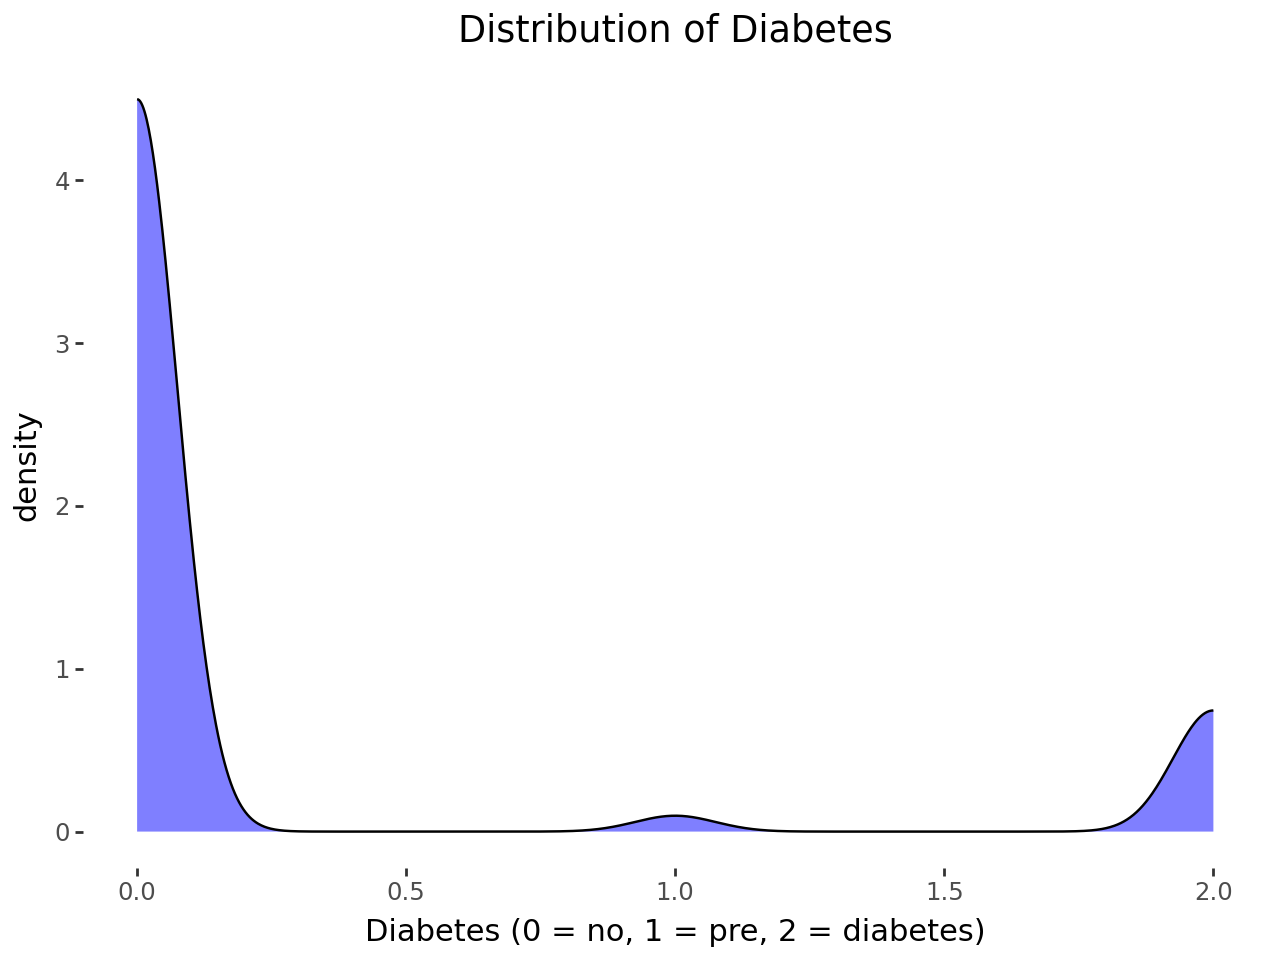

In [ ]:
g_1 = (
    ggplot(diabetes, aes(x="Diabetes_012")) # Set data and x-axis
    + geom_density(fill="blue", alpha=0.5) # Set geom_density
    + theme_bw() # Set theme
    + theme( # Turn off grid
        panel_grid_major=element_blank(),
        panel_grid_minor=element_blank(),
        panel_border=element_blank(),
        panel_background=element_blank()
    )
    + labs( # Set labels
        x="Diabetes (0 = no, 1 = pre, 2 = diabetes)",
        title="Distribution of Diabetes"
    )
)

# Generate plot
g_1

We can visualize a large class imbalance - where most of the values are Diabetes_012 = 0, meaning no Diabetes. Diabetes_012 = 1, Prediabetes, has the least amount of observations. Diabetes_012 = 2, has Diabetes, does have some observations, but much less compared to value 0. Two important considerations arise:

1. Doing something about the imbalanced class in our model
2. If 1 (prediabetes) is worth keeping as it barely has any observations and multiclass classification would turn out to be much harder than it should be compared to binary

In [ ]:
diabetes.isnull().sum()

,0
diabetes_01,0
HighBP,0
HighChol,0
CholCheck,0
BMI,0
Smoker,0
Stroke,0
HeartDiseaseorAttack,0
PhysActivity,0
Fruits,0


Data has no missing values.

## Plotting the independent variables by the dependent Diabetes_012 variable

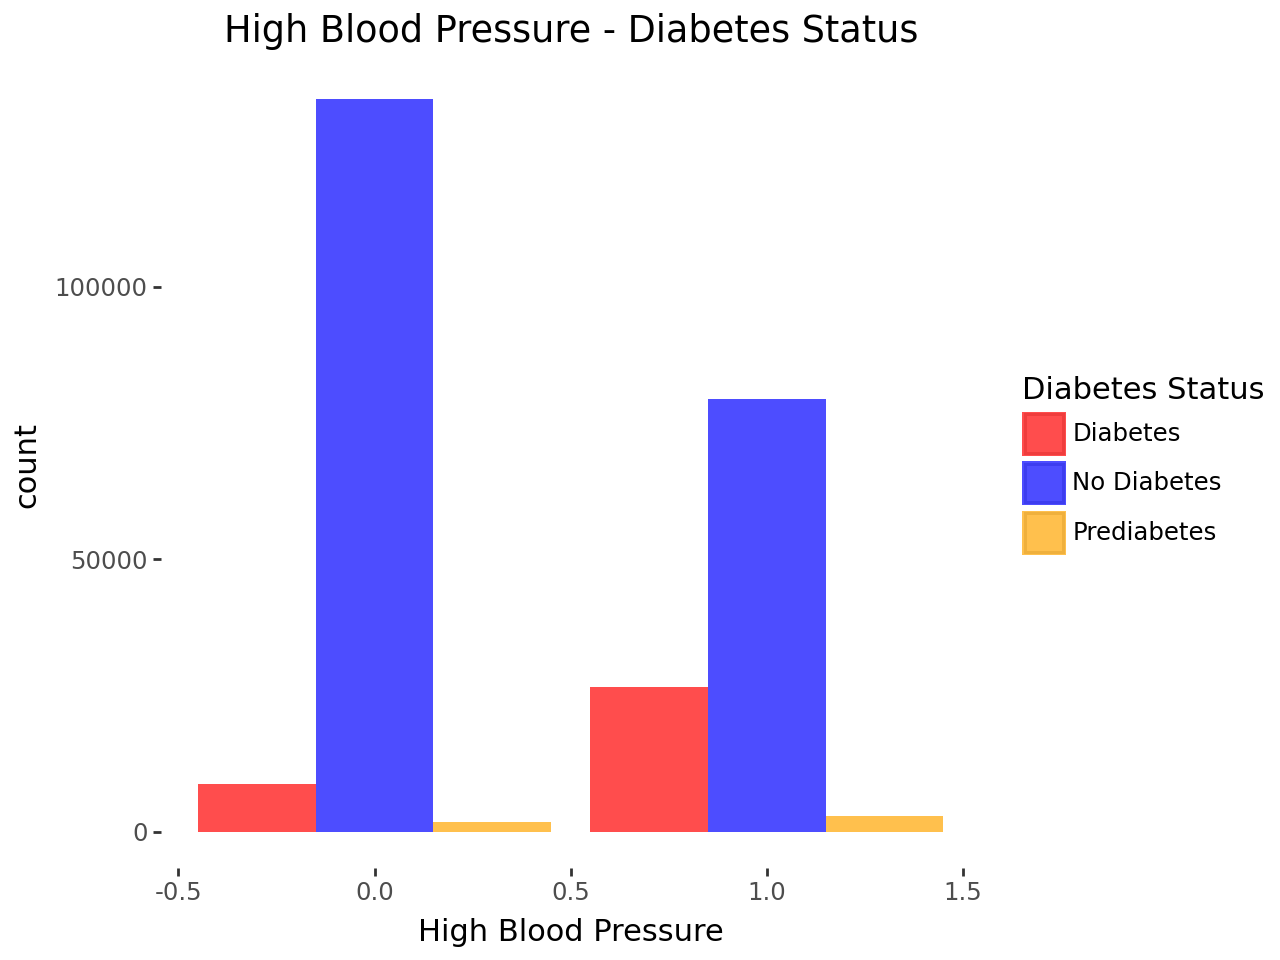

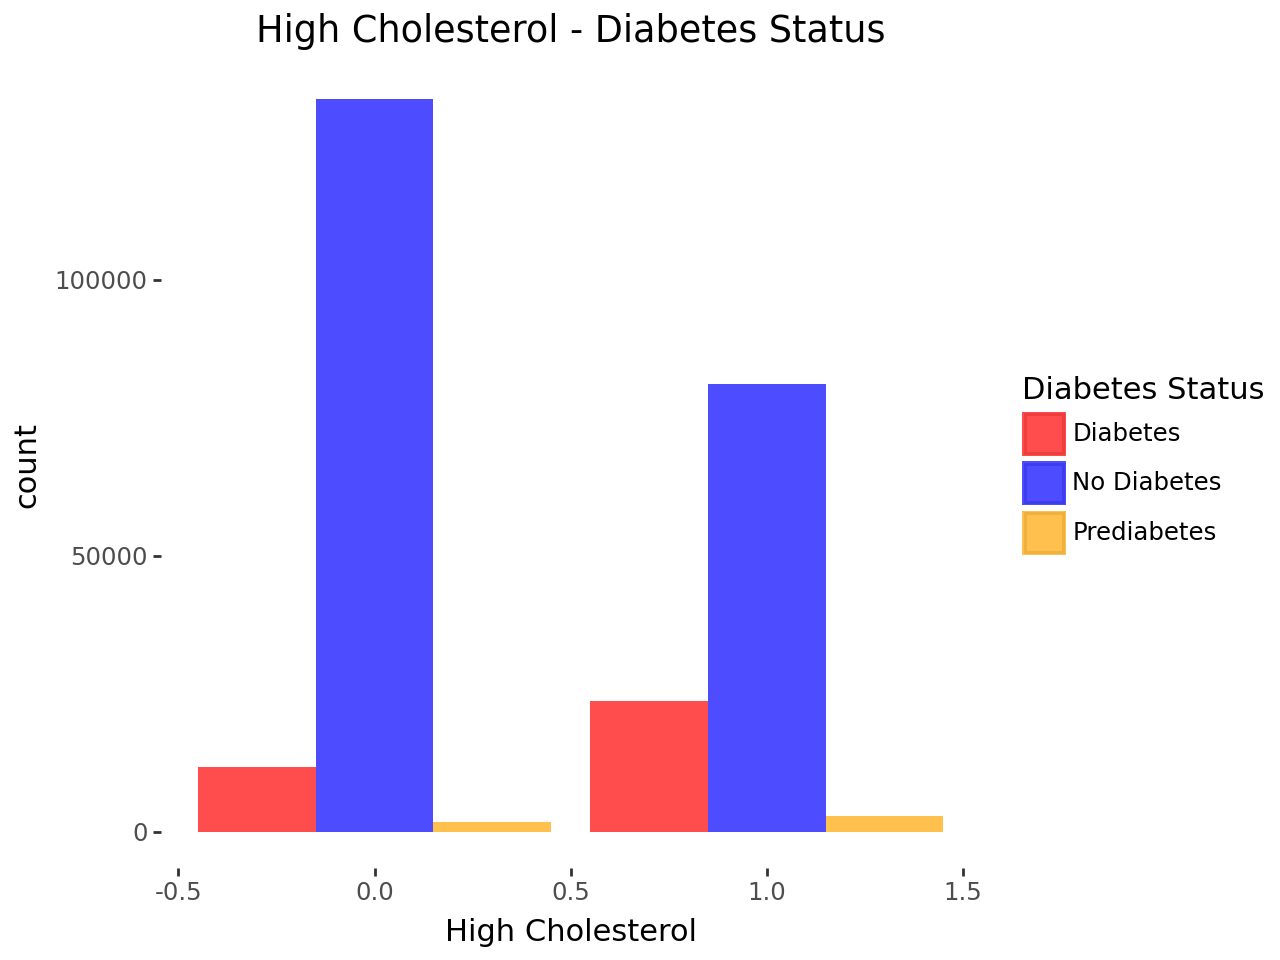

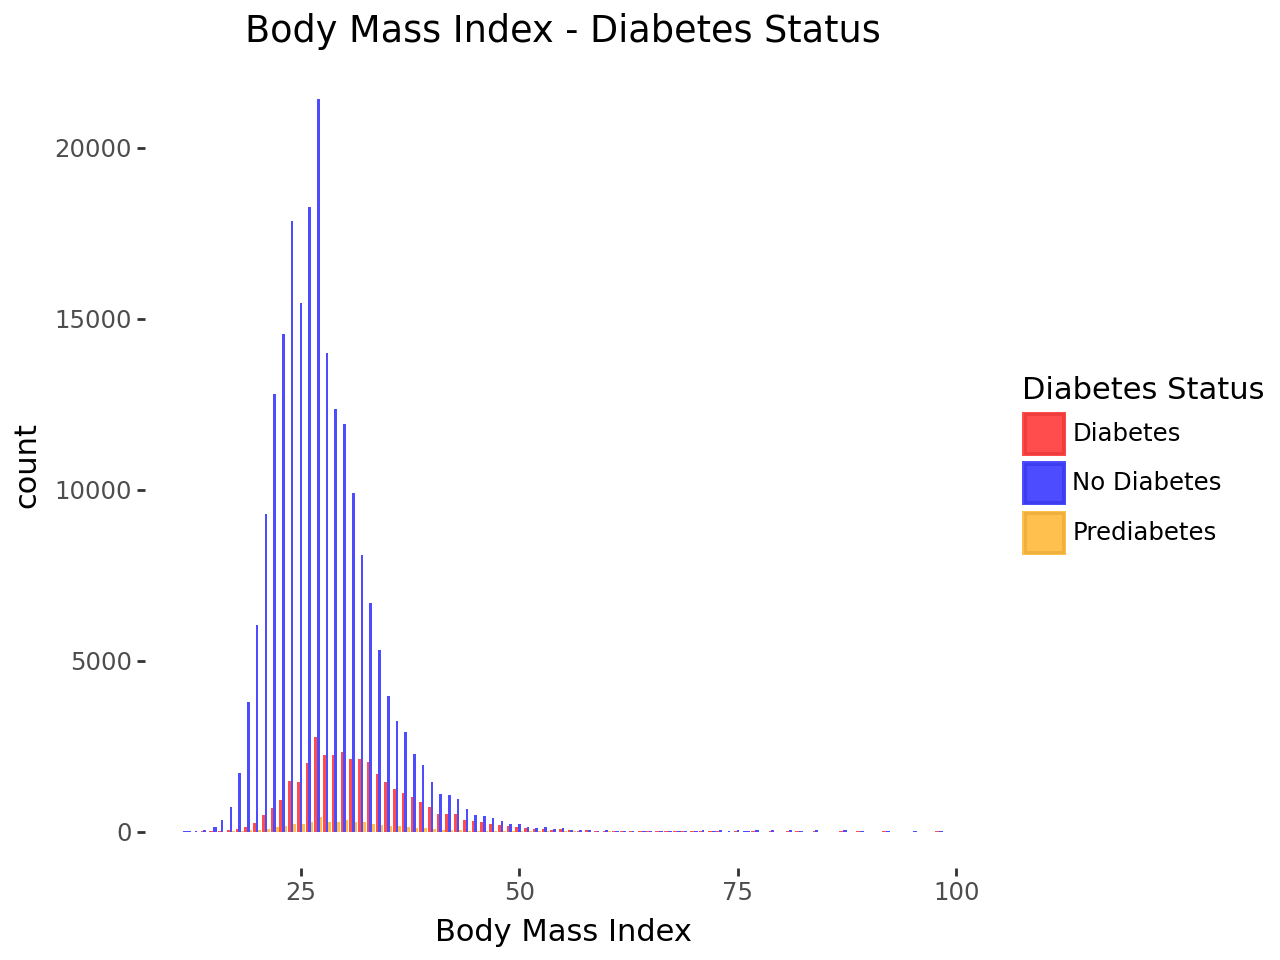

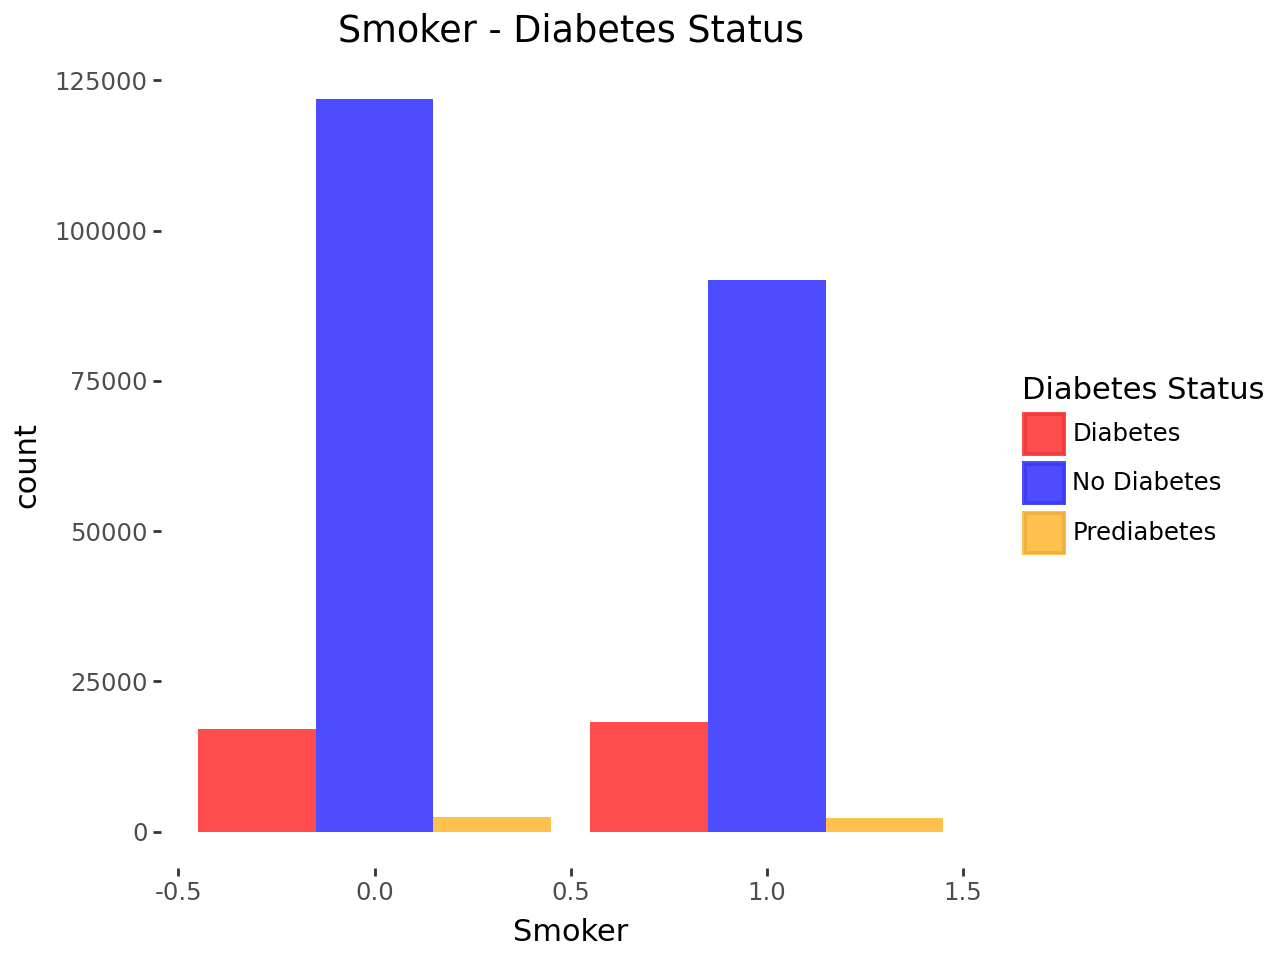

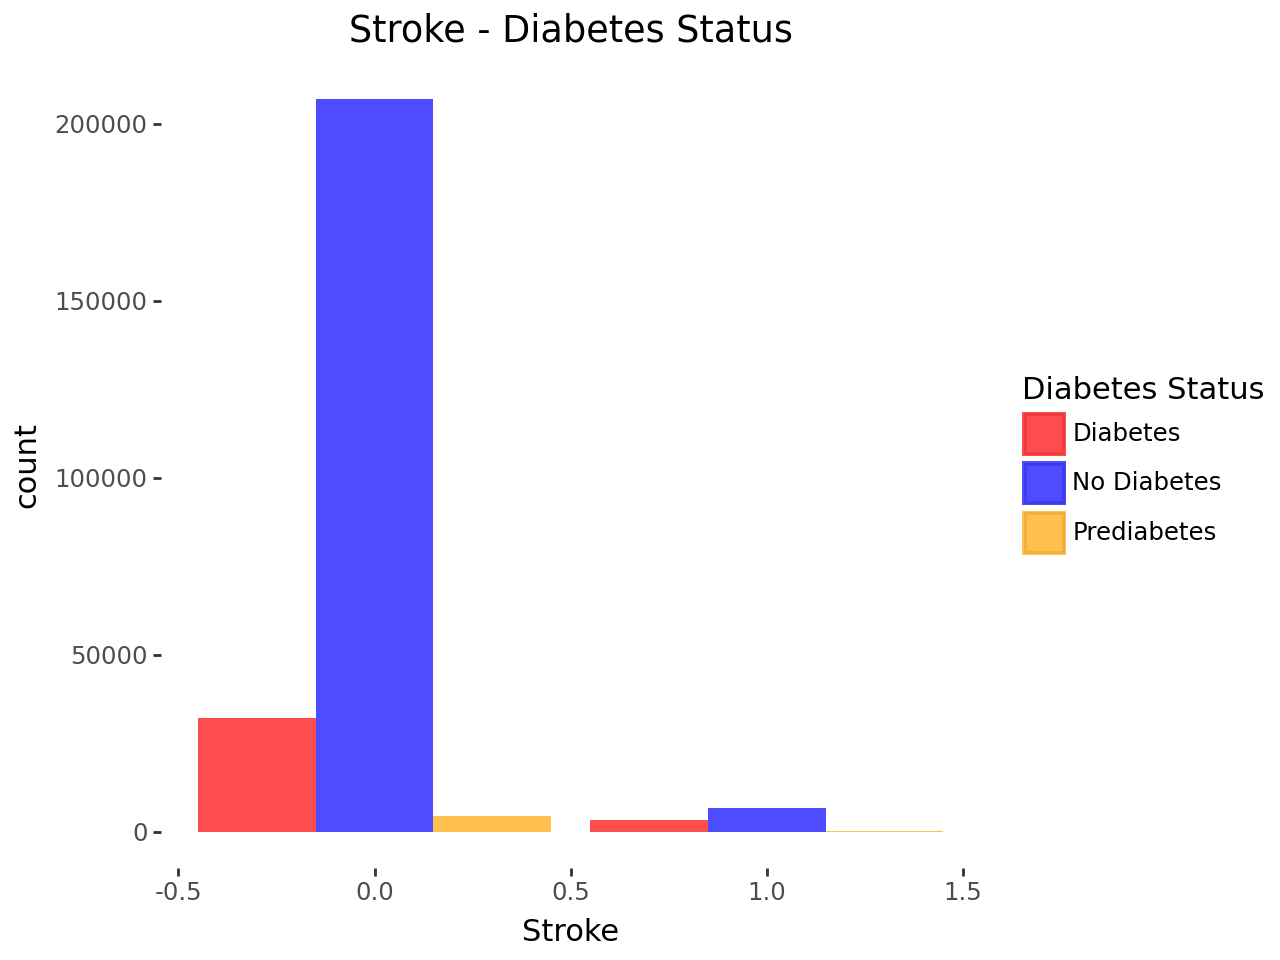

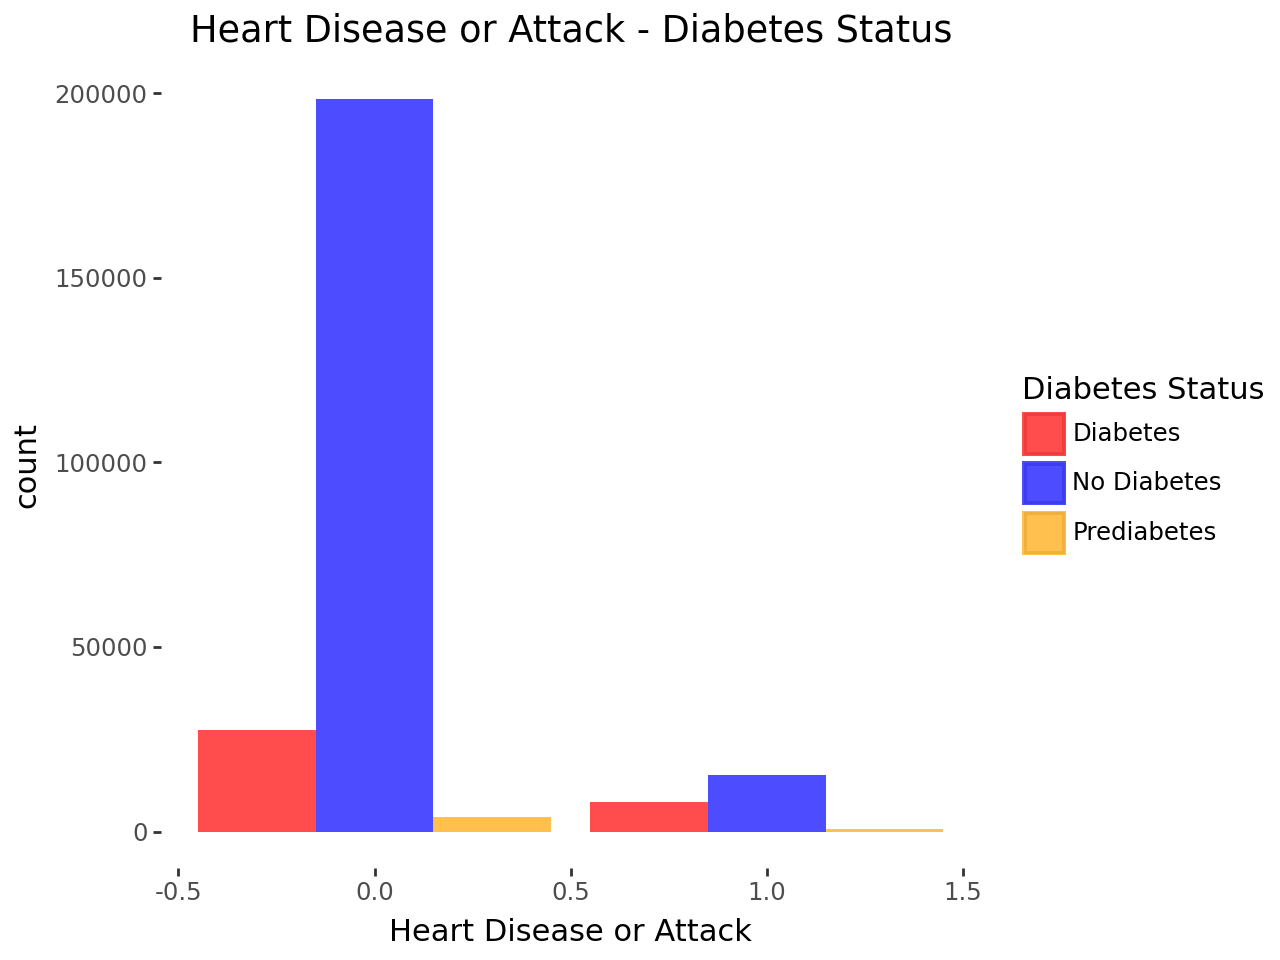

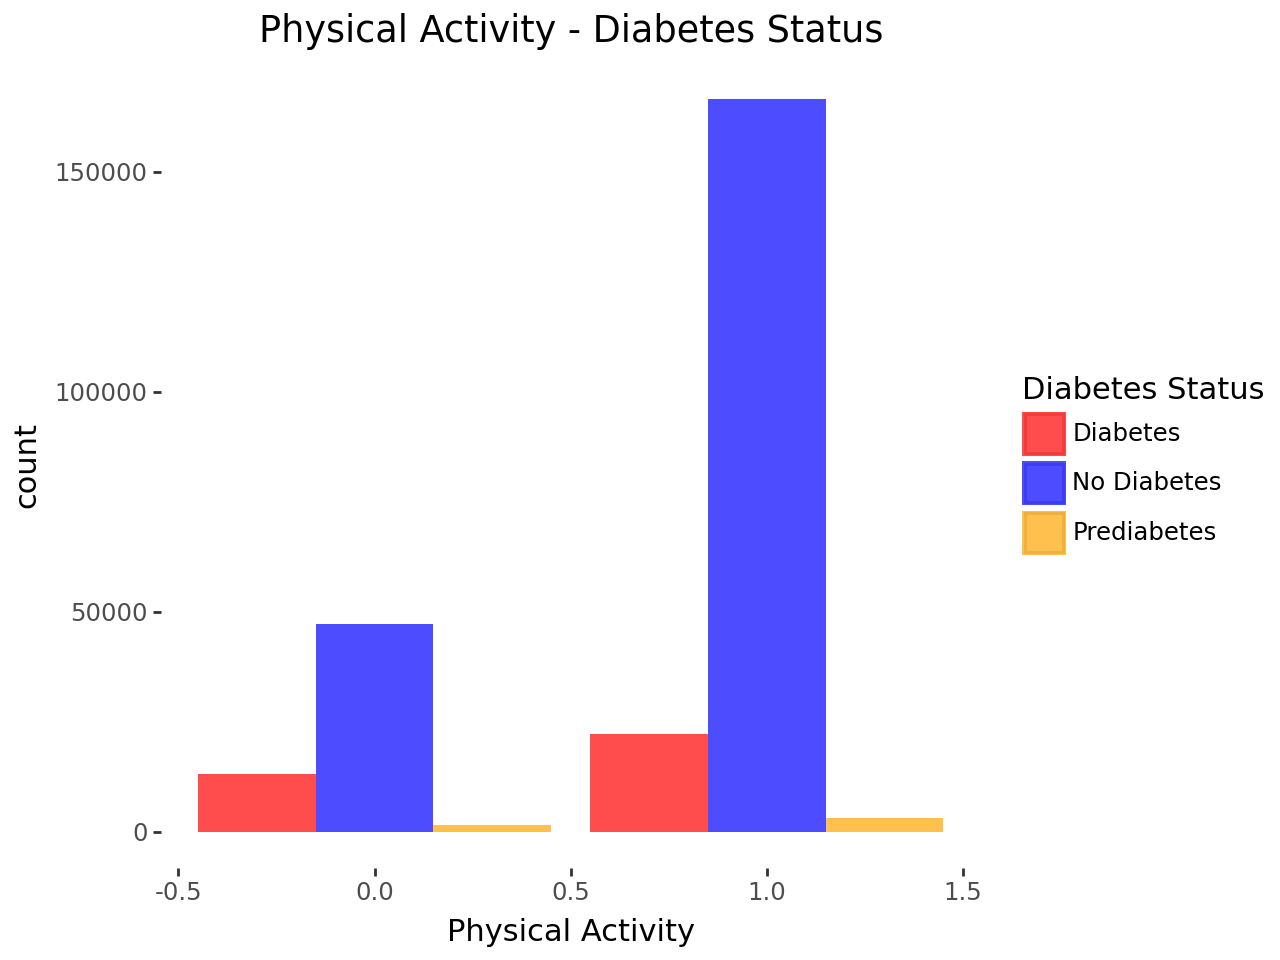

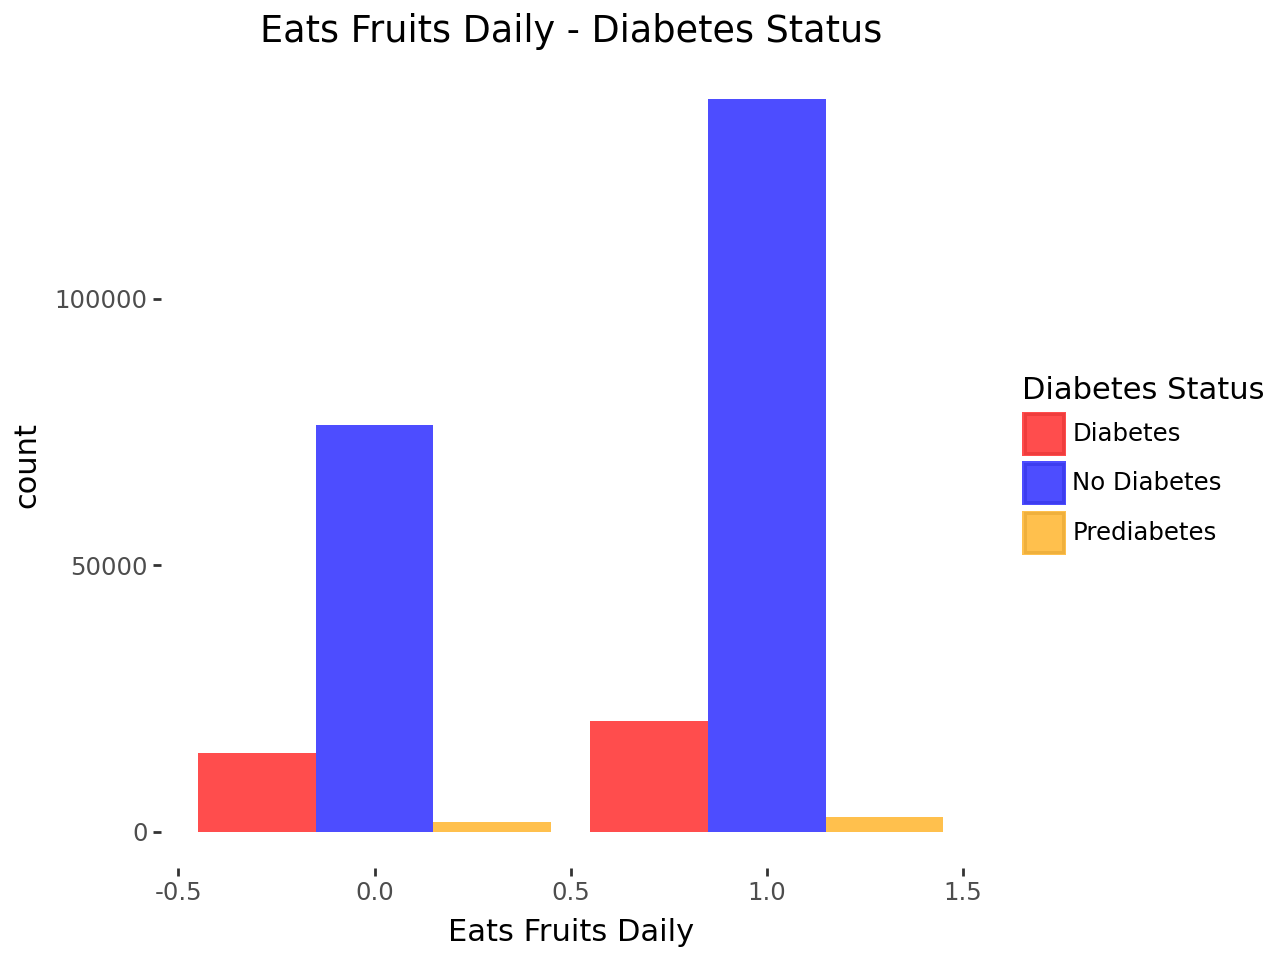

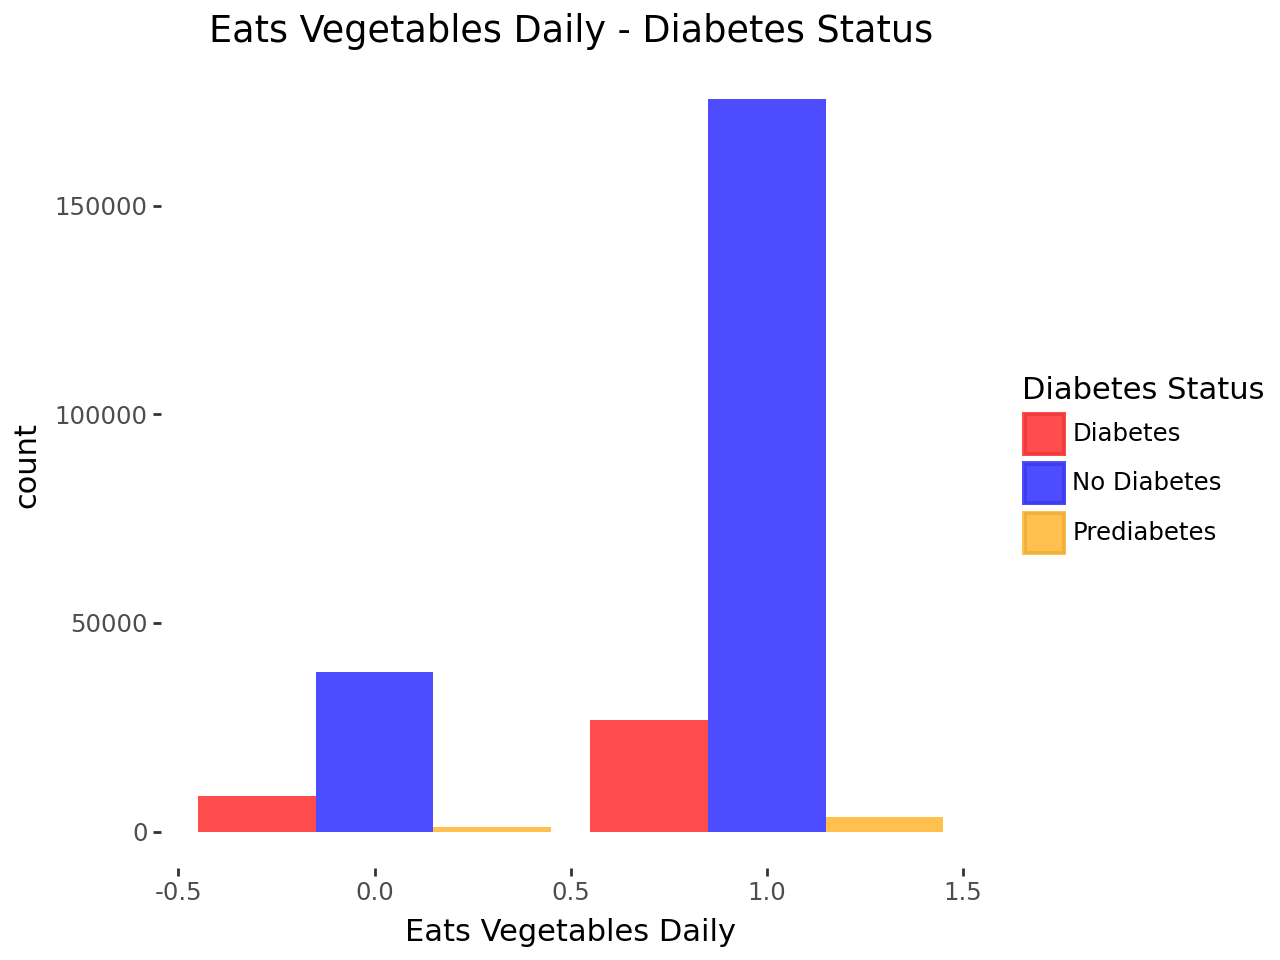

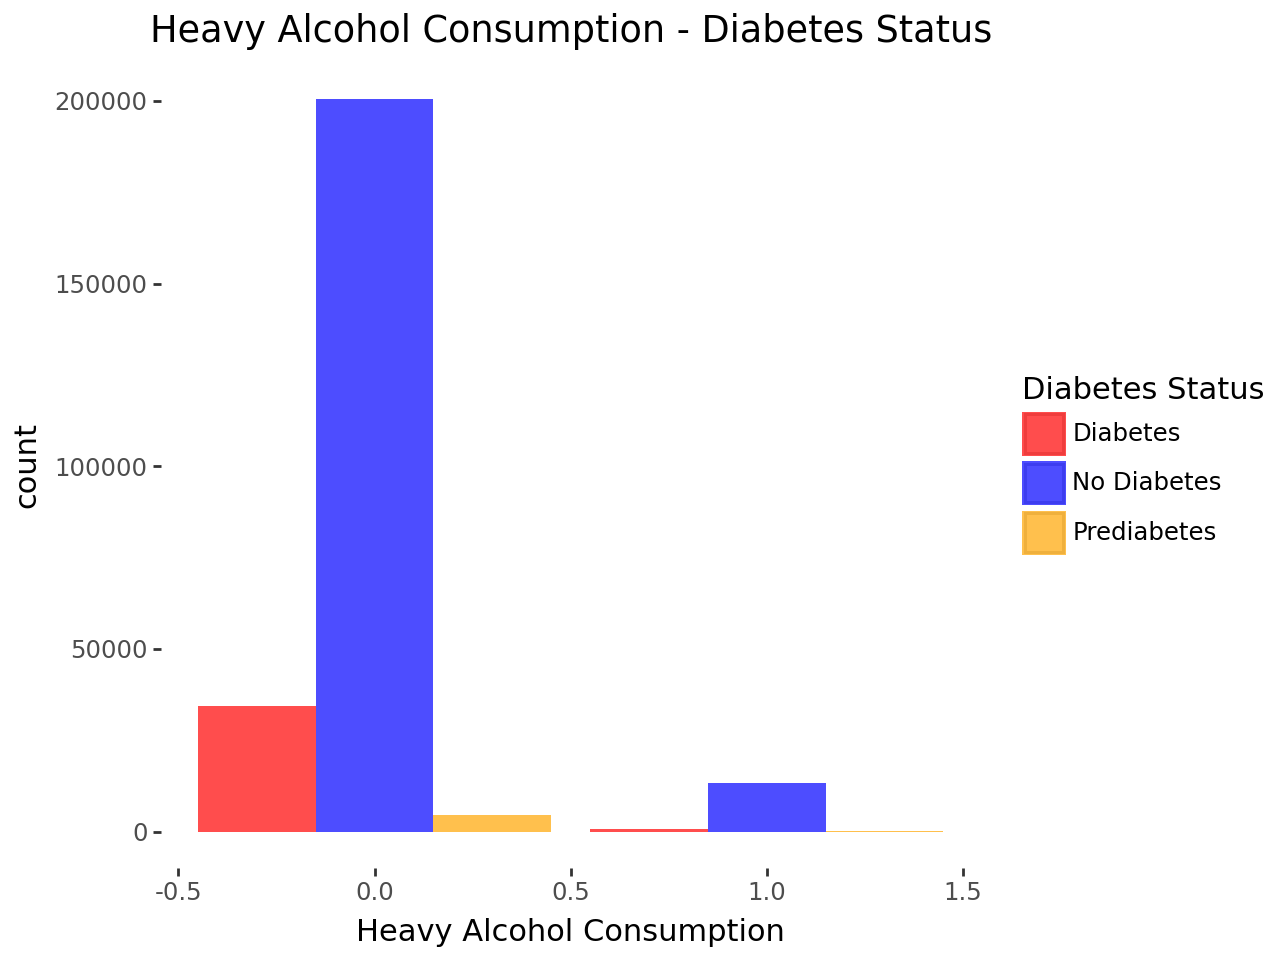

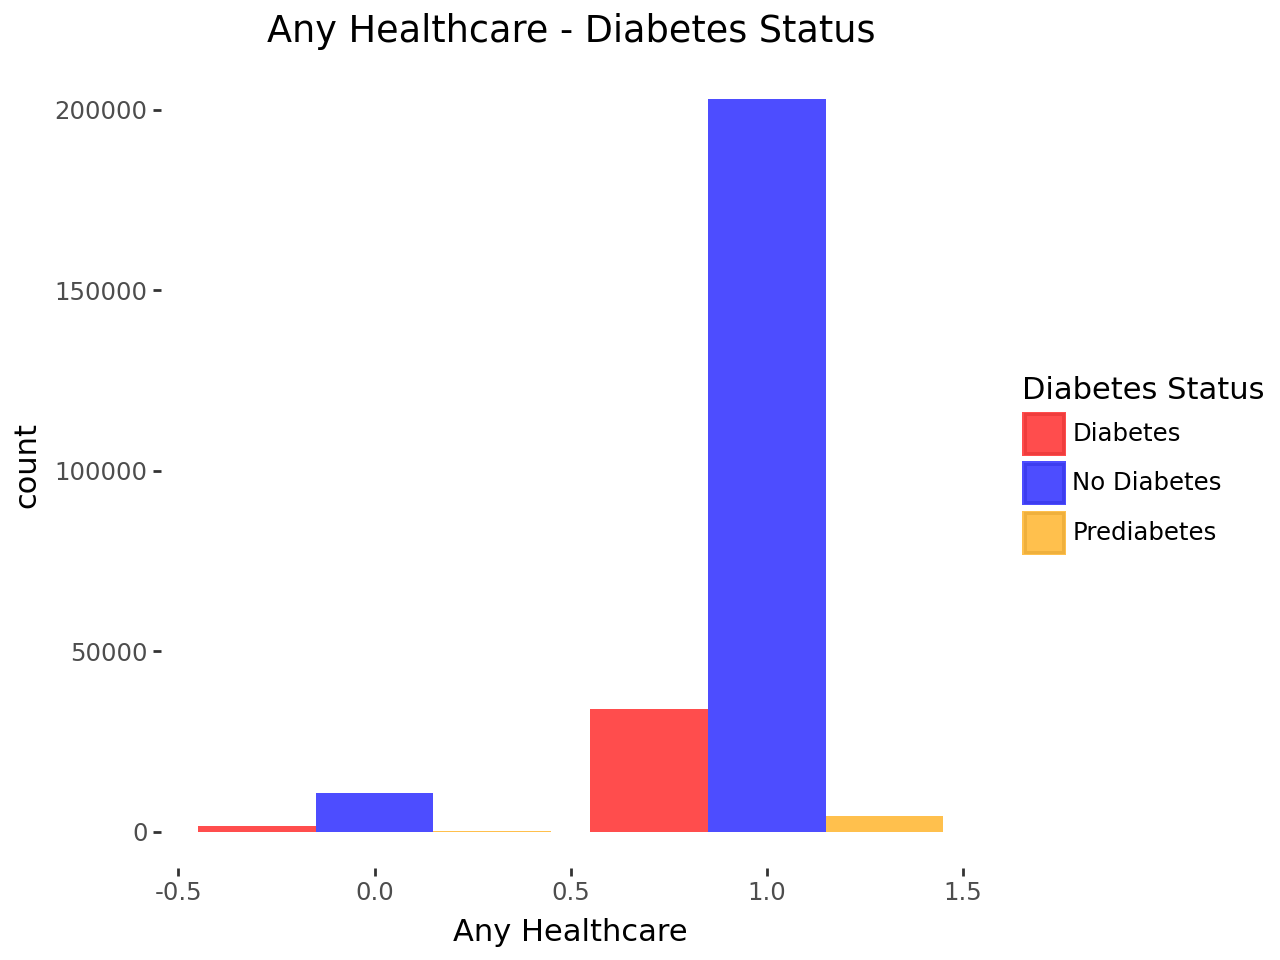

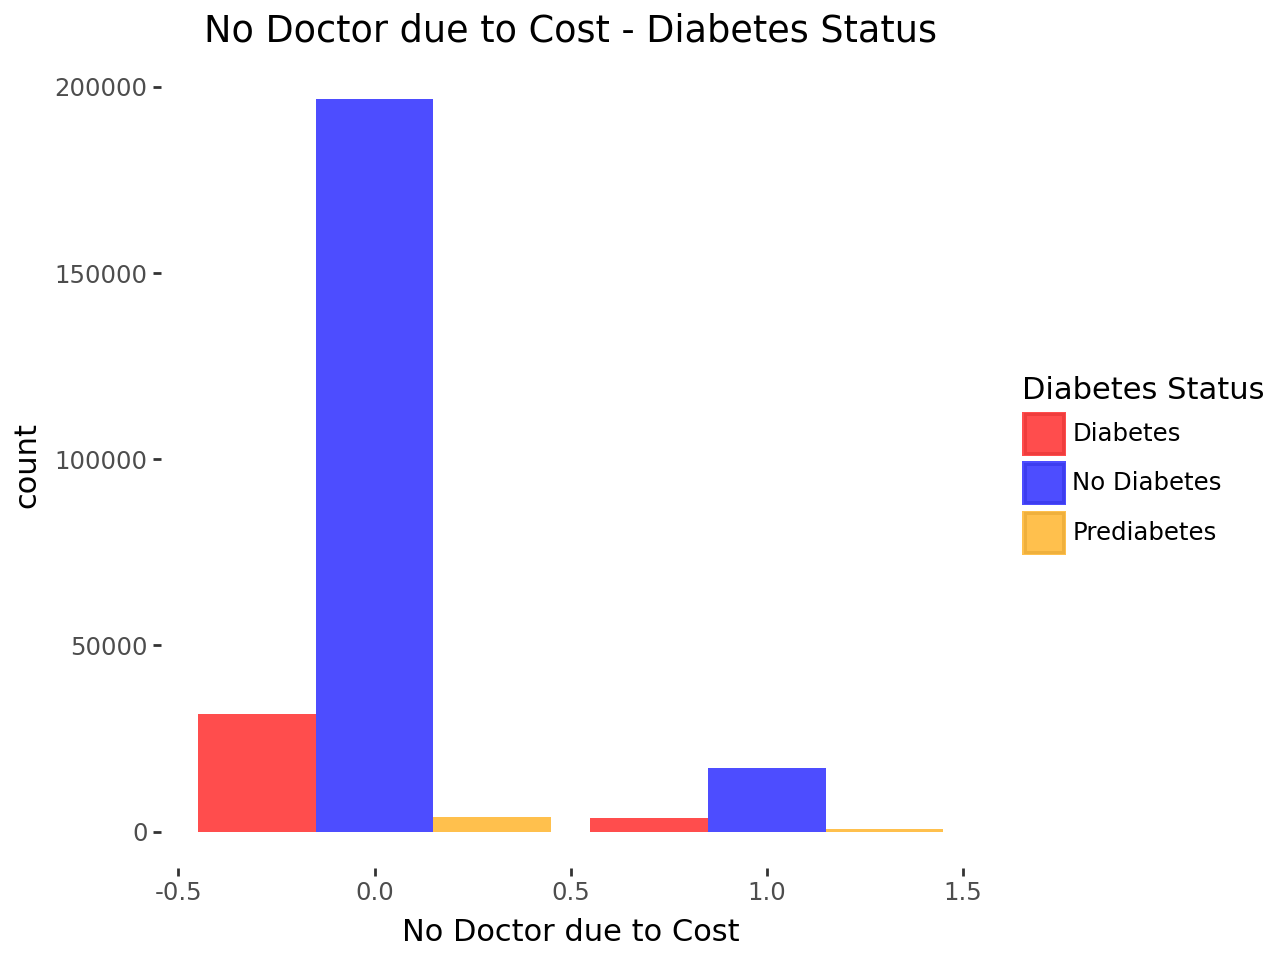

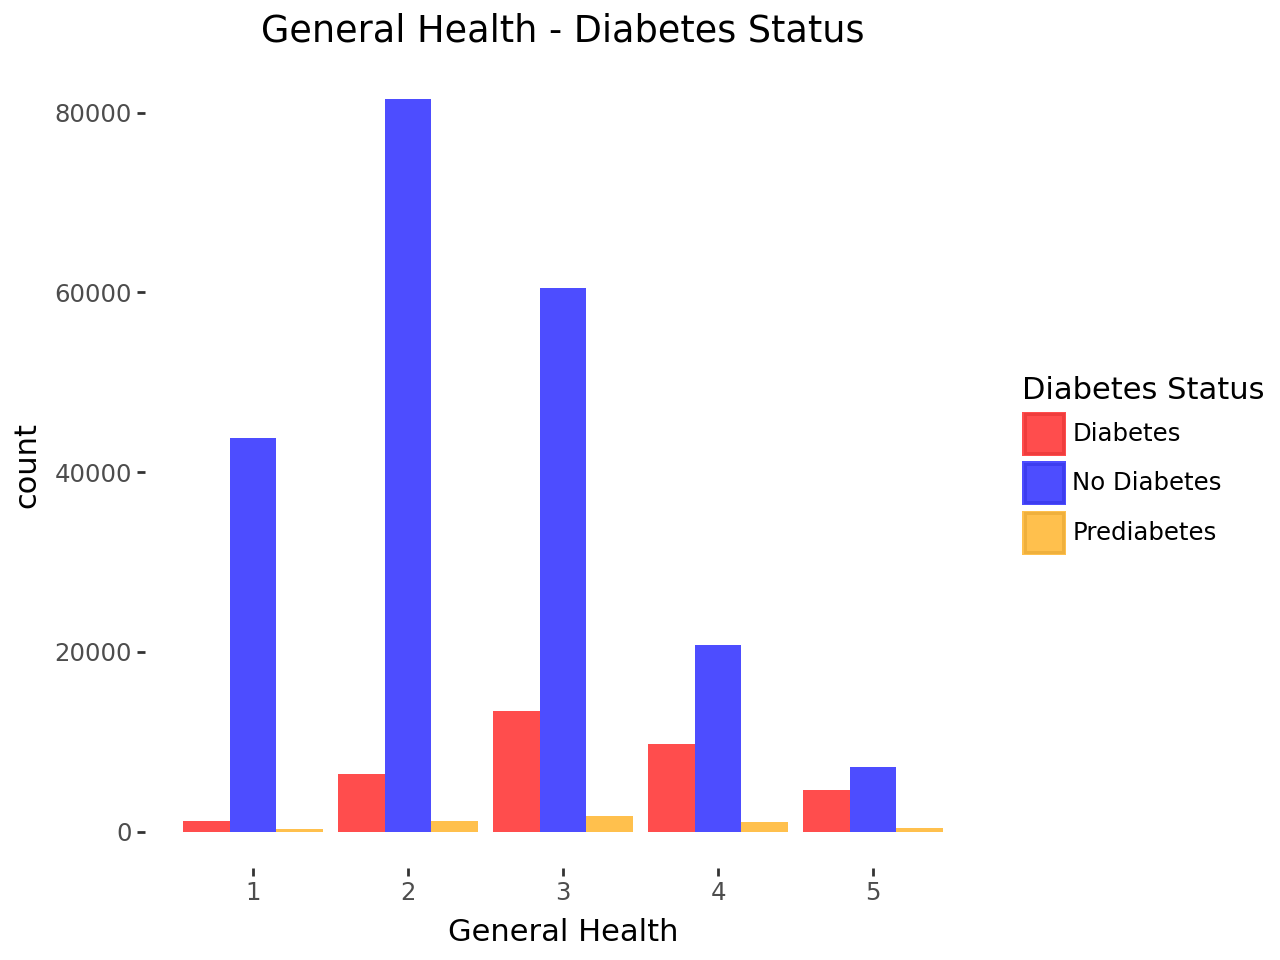

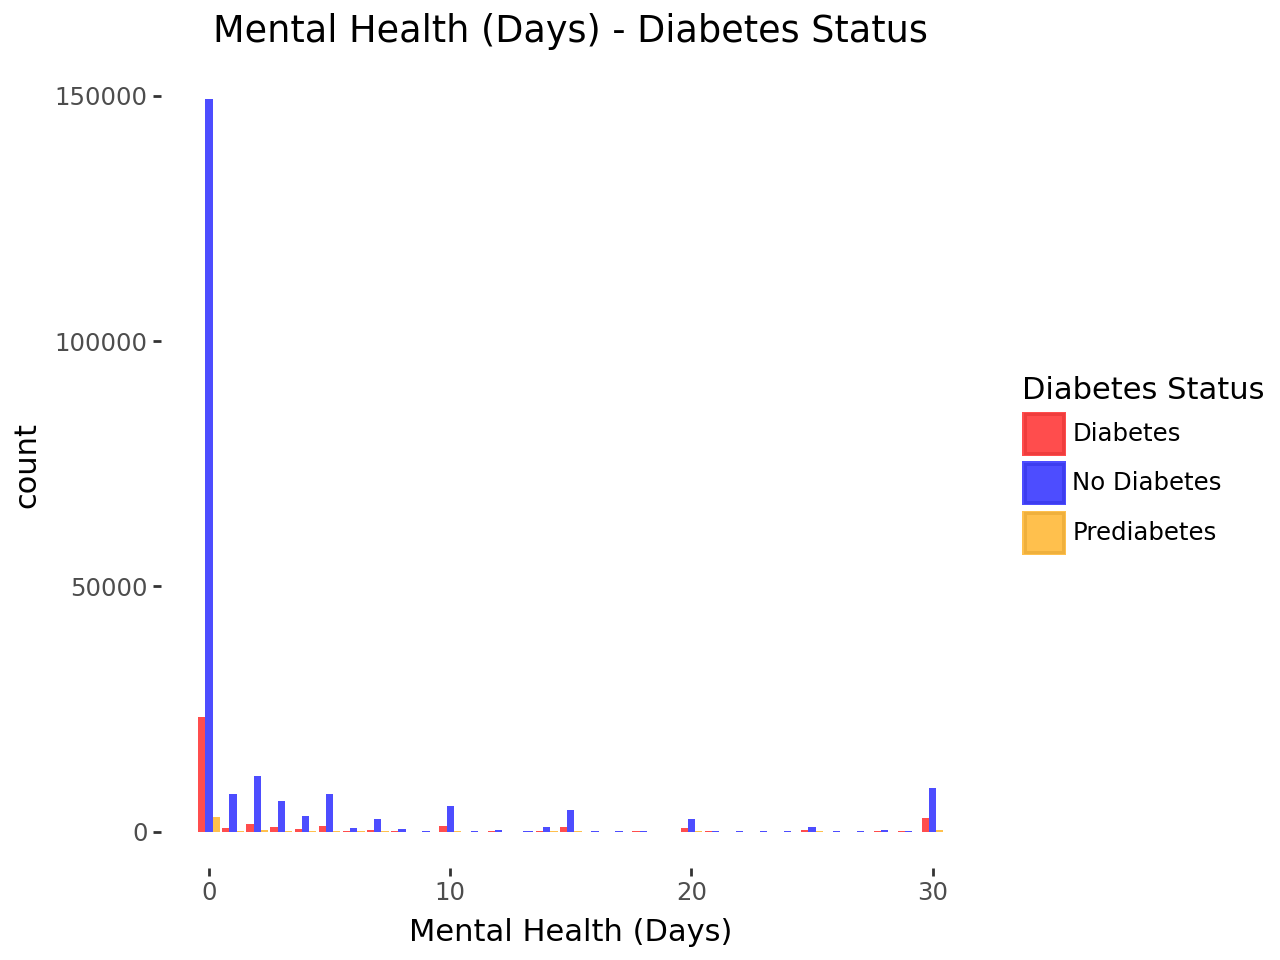

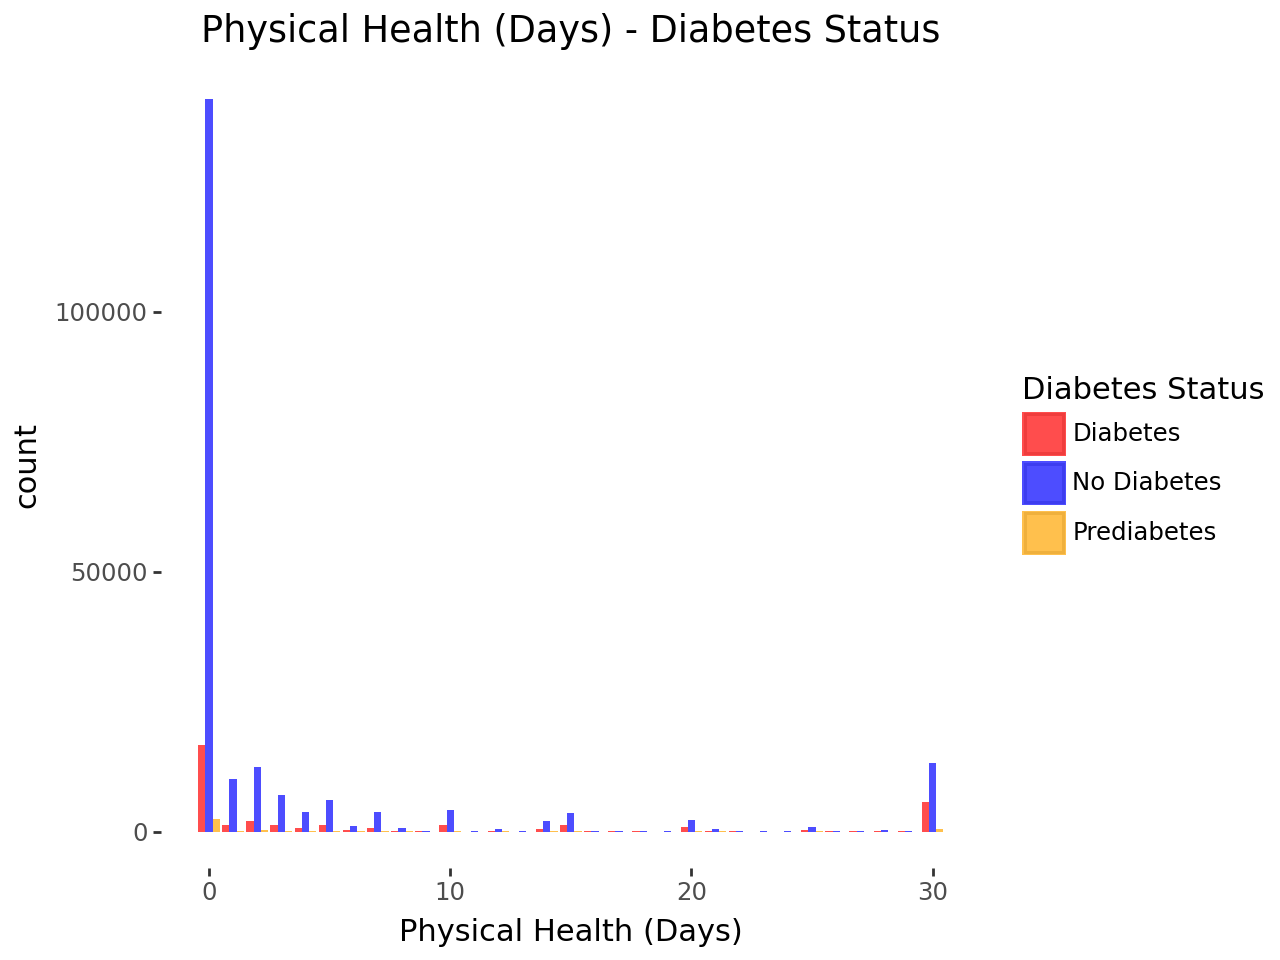

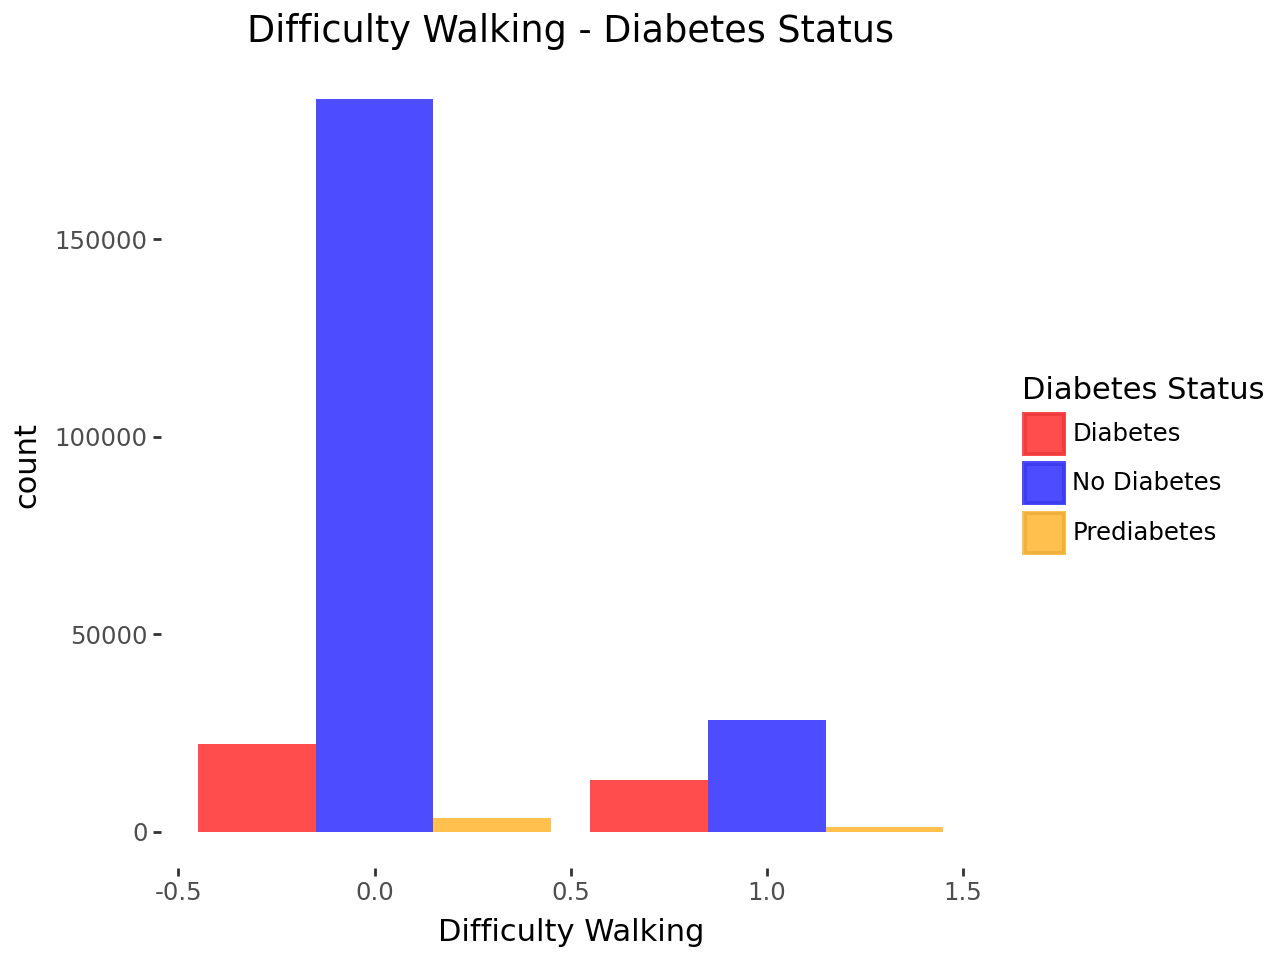

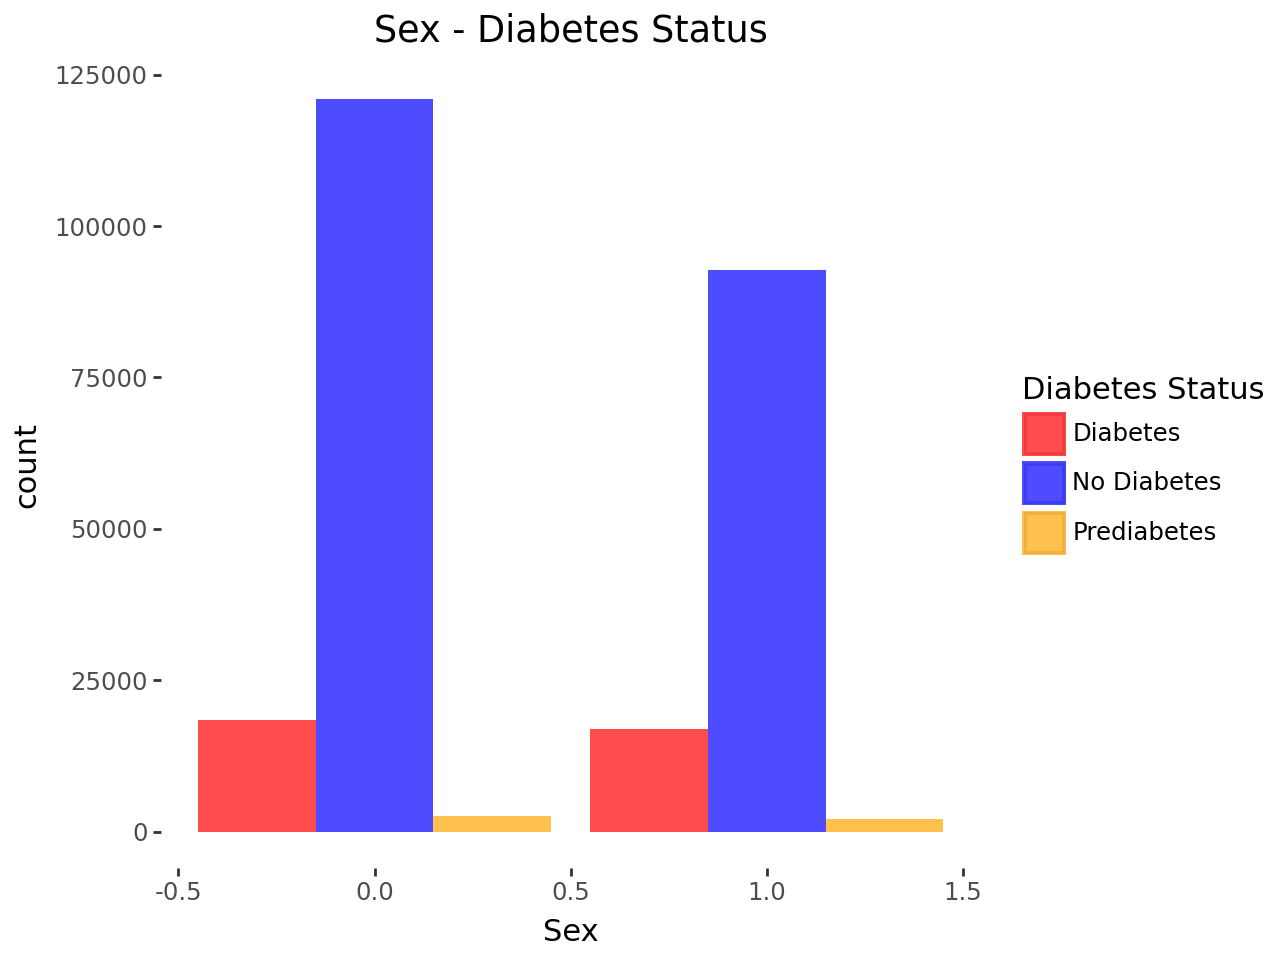

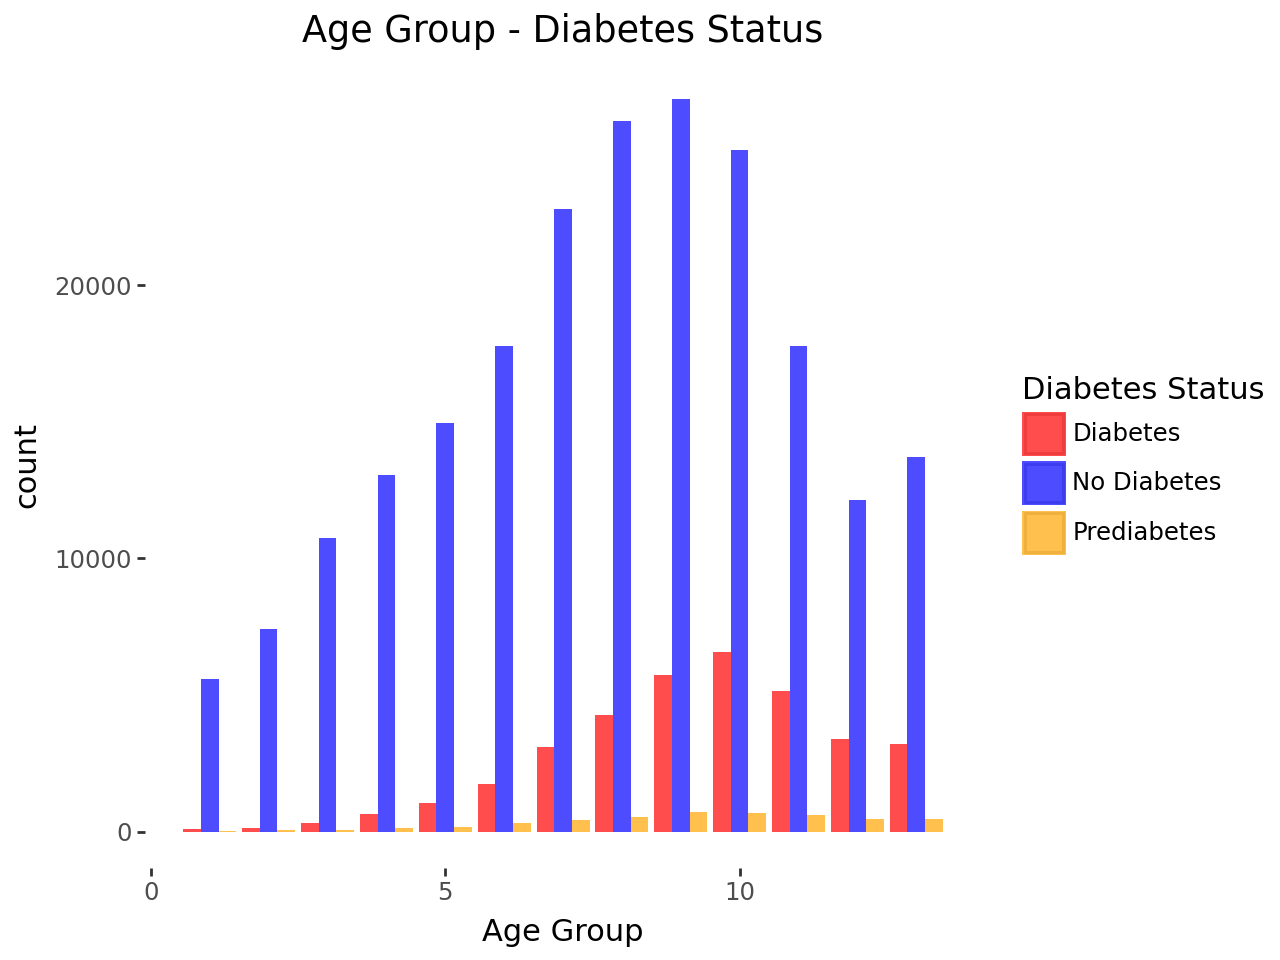

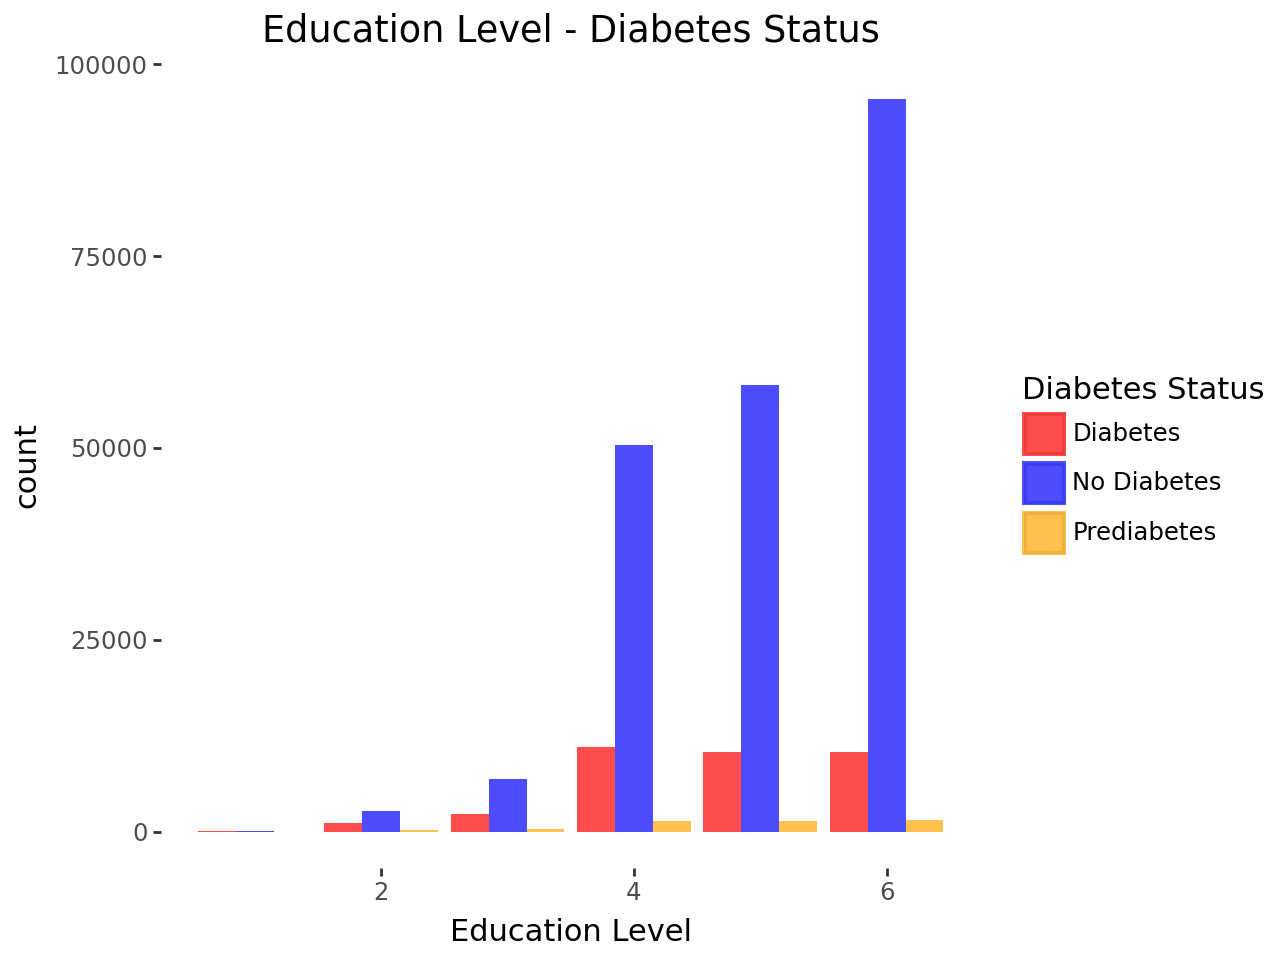

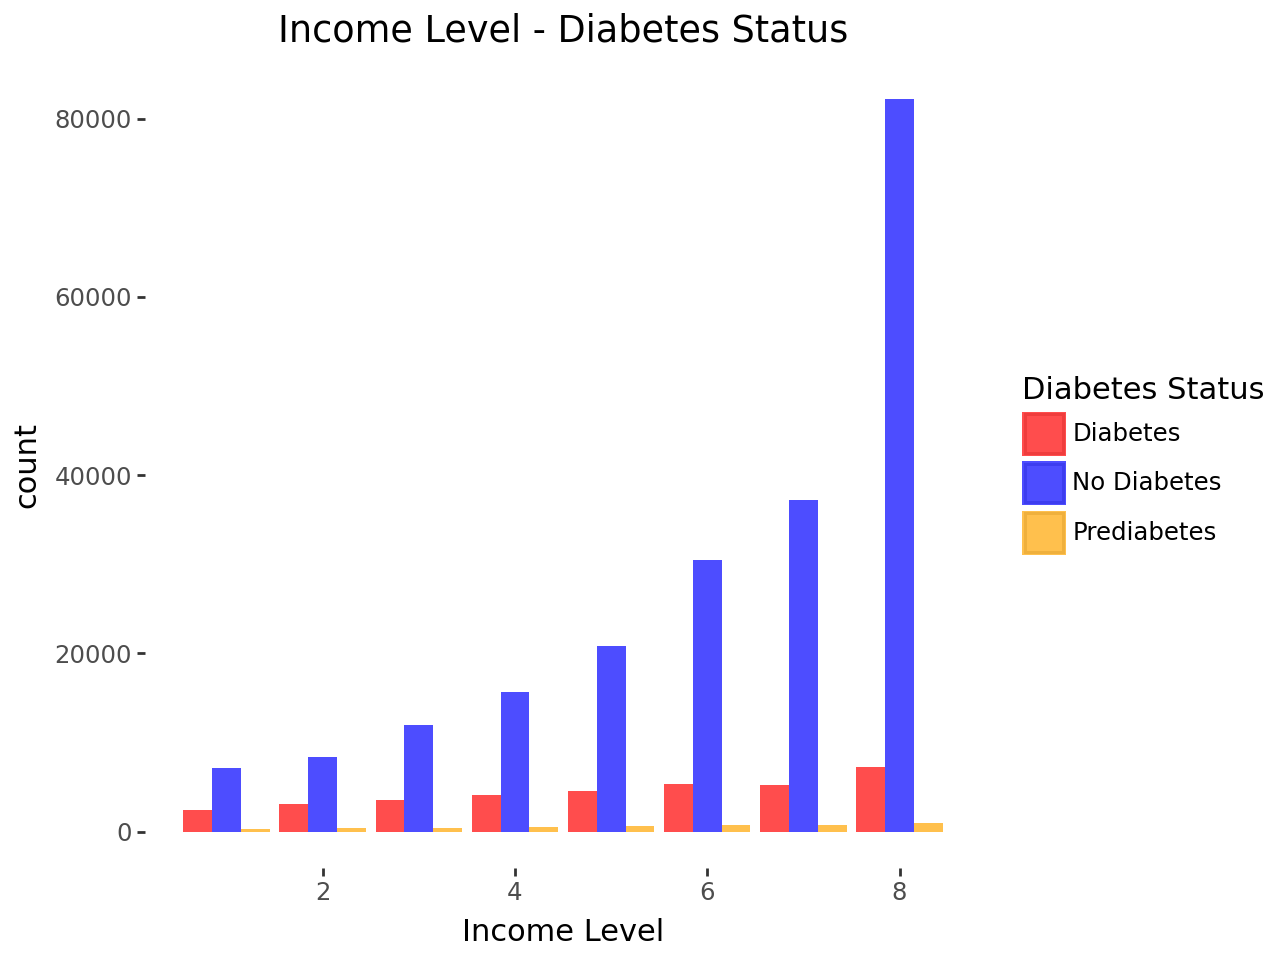

In [ ]:
# create data for plotting
plot_dat = diabetes.copy()

# label response
plot_dat['Diabetes_012'] = plot_dat['Diabetes_012'].map({2: 'Diabetes', 1: 'Prediabetes', 0: 'No Diabetes'})

# features and the axis labels
features = {
    'HighBP': 'High Blood Pressure',
    'HighChol': 'High Cholesterol',
    'BMI': 'Body Mass Index',
    'Smoker': 'Smoker',
    'Stroke': 'Stroke',
    'HeartDiseaseorAttack': 'Heart Disease or Attack',
    'PhysActivity': 'Physical Activity',
    'Fruits': 'Eats Fruits Daily',
    'Veggies': 'Eats Vegetables Daily',
    'HvyAlcoholConsump': 'Heavy Alcohol Consumption',
    'AnyHealthcare': 'Any Healthcare',
    'NoDocbcCost': 'No Doctor due to Cost',
    'GenHlth': 'General Health',
    'MentHlth': 'Mental Health (Days)',
    'PhysHlth': 'Physical Health (Days)',
    'DiffWalk': 'Difficulty Walking',
    'Sex': 'Sex',
    'Age': 'Age Group',
    'Education': 'Education Level',
    'Income': 'Income Level'
}

# one bar plot per feature
bar_plots = {}
for col, label in features.items():
    bar_plots[col] = (
        ggplot(plot_dat, aes(x=col, fill='Diabetes_012'))        # x as the feature, fill by diabetes status
        + geom_bar(alpha=0.7, position = "dodge")         # bar plot
        + theme_bw()                                      # set theme
        + theme(                                          # remove grid and borders
            panel_grid_major=element_blank(),
            panel_grid_minor=element_blank(),
            panel_border=element_blank(),
            panel_background=element_blank()
        )
        + labs(                                           # set labels
            x=label,
            title=f"{label} - Diabetes Status",
            fill="Diabetes Status"
        )
        + scale_fill_manual(                              # manual colors
            values={"Diabetes": "red", "Prediabetes": "orange", "No Diabetes": "blue"}
        )
    )

# display plots
for g in bar_plots.values():
    display(g)


Yet again, we depict the massive class imbalance, this time per individual variables - Diabetes vs No Diabetes still remains our main focus, but we decided to drop Prediabetes (Diabetes_012 = 1), with it barely having observations per variable and making it a multiclass classification problem would be unnecessarily problematic.

In [ ]:
diabetes = diabetes[diabetes['Diabetes_012'] != 1]

Also, we recoded and renamed the Diabetes_012 column. The variable is named diabetes_01, and value 0 remains no Diabetes, while value 1 now equals having Diabetes.

In [ ]:
diabetes['Diabetes_012'] = diabetes['Diabetes_012'].replace({2: 1})
diabetes = diabetes.rename(columns={'Diabetes_012': 'diabetes_01'})

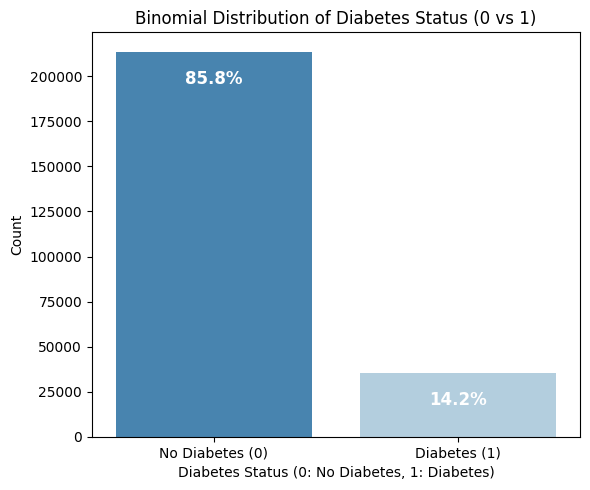

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count the occurrences of each class
class_counts = diabetes['diabetes_01'].value_counts().sort_index()

# Create a bar plot using matplotlib/seaborn to show the binomial (binary) distribution imbalance
plt.figure(figsize=(6, 5))
sns.barplot(x=class_counts.index, y=class_counts.values, palette='Blues_r', hue=class_counts.index, legend=False)

plt.title('Binomial Distribution of Diabetes Status (0 vs 1)')
plt.xlabel('Diabetes Status (0: No Diabetes, 1: Diabetes)')
plt.ylabel('Count')
plt.xticks(ticks=[0, 1], labels=['No Diabetes (0)', 'Diabetes (1)'])

# Display only the percentage, positioned directly on/inside the bars
total = len(diabetes)
for i, count in enumerate(class_counts):
    pct = (count / total) * 100
    # Place the text slightly below the top of each bar for better visibility
    plt.text(i, count - 15000, f'{pct:.1f}%', ha='center', va='center', color='white', fontweight='bold', fontsize=12)

plt.tight_layout()
plt.show()

In [ ]:
# Display the updated unique values and column name to confirm the changes
display(diabetes['diabetes_01'].unique())
display(diabetes.head())

array([0., 1.])

,diabetes_01,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


## Modeling

### Logistic Regression

In [ ]:
# Set up response
y = diabetes['diabetes_01']                                  # Response

# Get all columns except the target variable 'diabetes_01'
feature_columns = [col for col in diabetes.columns if col != 'diabetes_01']
features = {col: col for col in feature_columns}


# Fit a separate single variable logistic regression for each feature
univariate_fits = {}
for col in features:                                   # features was defined with the density plots
    X = sm.add_constant(diabetes[[col]])                   # Add intercept

    # Fit logistic regression (binomial with logit link)
    univariate_fits[col] = sm.Logit(y, X).fit(disp=False)

    # Summarize model
    print(univariate_fits[col].summary2())             # compact, structured summary table

# Collect the AICs in one place so we can compare them
aic_table = (
    pd.DataFrame({
        'feature': list(univariate_fits),
        'aic': [f.aic for f in univariate_fits.values()]
    })
    .sort_values('aic')
    .reset_index(drop=True)
)
display(aic_table)

                          Results: Logit
Model:              Logit            Method:           MLE        
Dependent Variable: diabetes_01      Pseudo R-squared: 0.090      
Date:               2026-10-02 16:31 AIC:              185216.1909
No. Observations:   249049           BIC:              185237.0417
Df Model:           1                Log-Likelihood:   -92606.    
Df Residuals:       249047           LL-Null:          -1.0172e+05
Converged:          1.0000           LLR p-value:      0.0000     
No. Iterations:     7.0000           Scale:            1.0000     
--------------------------------------------------------------------
          Coef.    Std.Err.       z       P>|z|     [0.025    0.975]
--------------------------------------------------------------------
const    -2.7326     0.0110   -247.5705   0.0000   -2.7542   -2.7110
HighBP    1.6403     0.0131    125.0605   0.0000    1.6146    1.6660

                          Results: Logit
Model:              Logit           

,feature,aic
0,GenHlth,181551.238074
1,HighBP,185216.190931
2,HighChol,192997.421824
3,DiffWalk,193021.042929
4,BMI,193053.533471
5,Age,194625.812799
6,Income,196873.500346
7,HeartDiseaseorAttack,196943.905804
8,PhysHlth,197062.058322
9,Education,199568.518666


In [ ]:
# constant for the intercept
X_train_const = sm.add_constant(X_train)

# logistic regression model
logit_model = sm.Logit(y_train, X_train_const).fit(disp=False)

# model summary
print(logit_model.summary2())

                           Results: Logit
Model:               Logit             Method:            MLE        
Dependent Variable:  diabetes_01       Pseudo R-squared:  0.217      
Date:                2026-10-02 20:50  AIC:               111581.7894
No. Observations:    174334            BIC:               111803.3014
Df Model:            21                Log-Likelihood:    -55769.    
Df Residuals:        174312            LL-Null:           -71205.    
Converged:           1.0000            LLR p-value:       0.0000     
No. Iterations:      8.0000            Scale:             1.0000     
---------------------------------------------------------------------
                      Coef.  Std.Err.    z     P>|z|   [0.025  0.975]
---------------------------------------------------------------------
const                -7.9870   0.1141 -70.0204 0.0000 -8.2105 -7.7634
HighBP                0.7623   0.0177  43.0144 0.0000  0.7275  0.7970
HighChol              0.6145   0.0163  37.5858 0

A Logistic Regression model is useful to see how each independent variable affects the model.

Instead of predicting the category directly, the model gives us probabilities that an individual has diabetes given their health profile (with log odds).

The highest positive coefficients (indicating the strongest factors of diabetes risk) include:

*   CholCheck (coefficient: 1.33, p value < 0.05) : Having a cholesterol check within the past 5 years is associated with a higher probability of being diagnosed with diabetes. People who are getting regular check ups are more likely to be diagnosed.
*   HighBP (coefficient: 0.61, p value < 0.05) : having high blood pressure is a big risk factor that is strongly associated with being diagnosed as having diabetes.
*   GenHlth (coefficient: 0.54, p value < 0.05) : where people reporting themselves as having poor health has a positive relationship with being diagnosed with diabetes.

The lowest negative coefficients include:

*   HvyAlcoholConsump (coefficient: -0.8114, p value < 0.05) : This one is intersting because heavy consumption of alcohol is associates with lower odds of being diagnosed with diabetes, at least in this sample. Some sort of bias (as many items are self reported by the people) or other things affecting this metric?
*   Income (coefficient: -0.05) and Education (coefficient: -0.04), both higher income and having more education are associated with lower odds of diabetes diagnosis. Socio-economic factors affecting health.
*   Fruits (coefficient: -0.05), Veggies (coefficient: -0.03), and PhysActivity (coefficient: -0.05) showing that the better one eats and more exercise one gets lowers the odds of being diagnosed with diabetes.

Some variables are statistically insignificant at the 95% confidence level (5% significance level)
*   Smoker (p value = 0.50), holding all other variables constant, being a smoker doesn't depict a statistically significant relationship with being diagnosed with diabetes, at least in this sample.
*   NoDocbcCost (pvalue = 0.17), likewise, not going to a doctor because of what it costs doesn't depict a statistically significant relationship with being diagnosed with diabetes, at least in this sample.

### Raw XGBoost

In [ ]:
X = diabetes.drop(columns=['diabetes_01'])
y = diabetes['diabetes_01']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")

X_train shape: (174334, 21)
X_test shape: (74715, 21)
y_train shape: (174334,)
y_test shape: (74715,)


Split the data 70% train 30%

In [ ]:
# Set up XGBDmatrix
# Passing the DataFrame itself (not .values) keeps our column names inside the model
dtrain = xgb.DMatrix(data=X_train, label=y_train)
dtest  = xgb.DMatrix(data=X_test,  label=y_test)

XGBoost uses its own data type called DMatrix that is an efficient method for storing sparse matrices (Many zeros).

In [ ]:
params = {
        "objective": "binary:logistic", # Set objective
        "eval_metric": ["auc", "error"],  # Track both AUC and error
        "tree_method": "hist", # Histogram splits - much faster, same answer on this data
        "seed": 123, # set seed
    }
num_boost_round = 1000 # Set number of rounds

Set the base parameters and set the number of rounds as 1000 to start.

In [ ]:
watchlist = [(dtrain, "train")] # Set data for evaluation
booster = xgb.train(params, # Set parameters
                    dtrain,  # Set training data
                    num_boost_round=num_boost_round, # Set number of rounds
                    evals=watchlist,  # Set data to evaluate on
                    verbose_eval=50) # Set print out frequency

[0]	train-auc:0.81919	train-error:0.14192
[50]	train-auc:0.85309	train-error:0.12829
[100]	train-auc:0.86287	train-error:0.12370
[150]	train-auc:0.87228	train-error:0.11892
[200]	train-auc:0.88024	train-error:0.11531
[250]	train-auc:0.88685	train-error:0.11110
[300]	train-auc:0.89215	train-error:0.10825
[350]	train-auc:0.89768	train-error:0.10569
[400]	train-auc:0.90288	train-error:0.10264
[450]	train-auc:0.90690	train-error:0.10023
[500]	train-auc:0.91037	train-error:0.09756
[550]	train-auc:0.91329	train-error:0.09579
[600]	train-auc:0.91724	train-error:0.09309
[650]	train-auc:0.92097	train-error:0.09115
[700]	train-auc:0.92385	train-error:0.08897
[750]	train-auc:0.92625	train-error:0.08735
[800]	train-auc:0.92902	train-error:0.08562
[850]	train-auc:0.93166	train-error:0.08422
[900]	train-auc:0.93416	train-error:0.08261
[950]	train-auc:0.93643	train-error:0.08091
[999]	train-auc:0.93835	train-error:0.07920


The AUC increases and Error decreases as seen every 50 rounds.

In [ ]:
test_pred_raw = booster.predict(dtest) # Create predictions
test_pred_raw

array([0.00491178, 0.11051694, 0.00022555, ..., 0.06504797, 0.09244525,
       0.18152896], dtype=float32)

To predict with XGBoost we can use the predict() function which we have used for other models.

In [ ]:
# Convert predictions into classes at 0.5
test_pred_cls = (test_pred_raw >= 0.5).astype(int)

We have numeric probabilities, so we convert these to classes by setting a threshold of 0.5.


Confusion matrix:


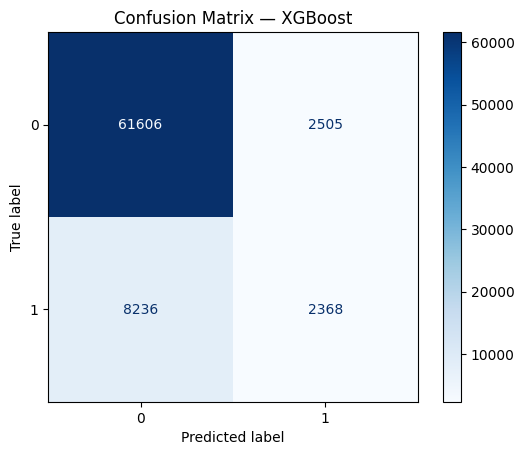


Accuracy):
0.8562403801110888


In [ ]:
print("\nConfusion matrix:")
cm = (confusion_matrix(y_test, test_pred_cls))
disp = ConfusionMatrixDisplay(confusion_matrix=cm)# Set class labels
disp.plot(cmap="Blues") # Set color map
plt.title("Confusion Matrix — XGBoost") # Set title
plt.show() # Display plot
print("\nAccuracy):")
print(accuracy_score(y_test, test_pred_cls)) # Get classification report

*   True Negatives (True Label 0 : Predicted 0) - 61,606
*   False Positives (True Label 0 : Predicted 1) - 2,505
*   False Negatives (True Label 1 : Predicted 0) - 8,236
*   True Positives (True Label 1 : Predicted 1) - 2,368

We are in 85.6% accuracy, which is great - the big issue here is sensitivity (recall), calculated as TPs / (TPs + FNs) = 2368 / (2368 + 8235) = 0.22 or 22%. Meaning that the raw XGB is only catching approx. 22% of the positive cases in the data.

## Tuning XGB

Running our algorithm with a high number of trees and a learning rate of 0.1 to determine an appropriate number of trees to use.

In [ ]:
params = {
    "objective": "binary:logistic",   # Set objective
    "eta": 0.1,                       # Set learning rate
    "eval_metric": ["auc", "error"],  # Track both AUC and error
    "tree_method": "hist",
    "seed": 111111,
}

# The cross-validation itself - 400 rounds on five folds
def run_baseline_cv():
    return xgb.cv(                  #doesnt need to look at external data - this is internal xbg cross validation
        params=params,
        dtrain=dtrain,              # Training data (DMatrix)
        num_boost_round=400,       # Number of rounds
        nfold=5,                    # 5-fold CV
        verbose_eval=50,            # Print every 20 iters
        stratified=True,            # Good practice for classification
        shuffle=True,
    )

cv1 = run_baseline_cv()


[0]	train-auc:0.81983+0.00058	train-error:0.14192+0.00000	test-auc:0.81589+0.00215	test-error:0.14192+0.00001
[50]	train-auc:0.84481+0.00034	train-error:0.13238+0.00012	test-auc:0.83410+0.00154	test-error:0.13443+0.00047
[100]	train-auc:0.85096+0.00043	train-error:0.12953+0.00028	test-auc:0.83430+0.00145	test-error:0.13458+0.00054
[150]	train-auc:0.85554+0.00057	train-error:0.12723+0.00044	test-auc:0.83378+0.00137	test-error:0.13483+0.00026
[200]	train-auc:0.85935+0.00077	train-error:0.12531+0.00041	test-auc:0.83311+0.00155	test-error:0.13518+0.00023
[250]	train-auc:0.86312+0.00104	train-error:0.12374+0.00053	test-auc:0.83249+0.00155	test-error:0.13541+0.00026
[300]	train-auc:0.86580+0.00108	train-error:0.12230+0.00050	test-auc:0.83193+0.00158	test-error:0.13567+0.00031
[350]	train-auc:0.86889+0.00160	train-error:0.12088+0.00068	test-auc:0.83123+0.00158	test-error:0.13591+0.00040
[399]	train-auc:0.87235+0.00146	train-error:0.11894+0.00062	test-auc:0.83052+0.00164	test-error:0.13610+0.0

What the best iteration was:

In [ ]:
# best iteration - where error was lowest
best_idx = cv1['test-error-mean'].idxmin()
best_iter = int(best_idx) + 1 # Increment by 1 to get iteration
best_err  = float(cv1.loc[best_idx, 'test-error-mean']) # Extract test error
best_auc  = float(cv1.loc[best_idx, 'test-auc-mean']) if 'test-auc-mean' in cv1.columns else np.nan # Extract test AUC

# Print results
print(f"Best iteration (by min test error): {best_iter}")
print(f"Min test error at best iter: {best_err:.6f}")
if not np.isnan(best_auc):
    print(f"Test AUC at best iter: {best_auc:.6f}")

Best iteration (by min test error): 65
Min test error at best iter: 0.134237
Test AUC at best iter: 0.834350


Visualizing the performance for different numbers of iterations:

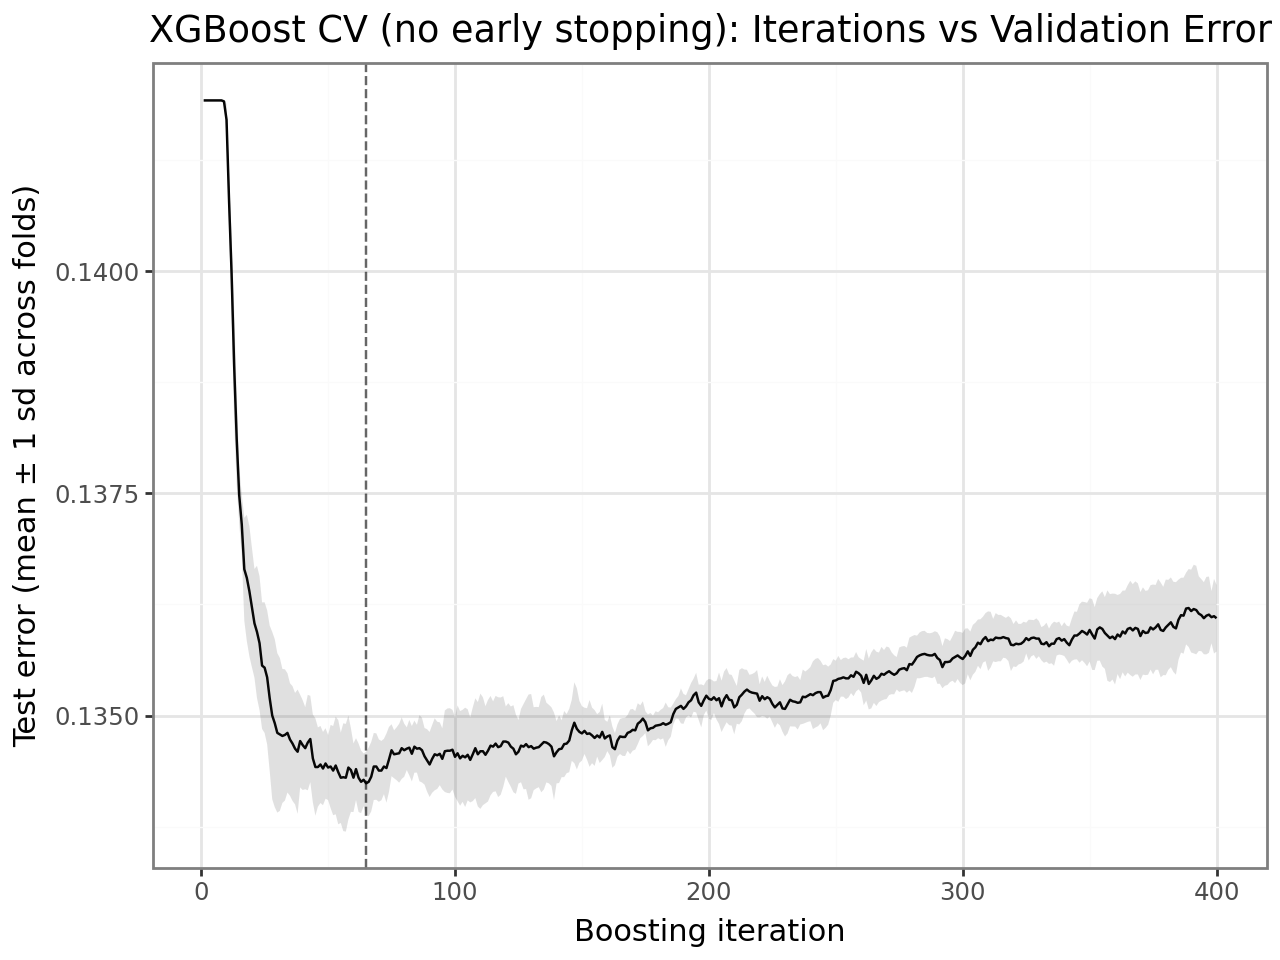

In [ ]:
df_plot = cv1.reset_index().rename(columns={"index": "iter"})
df_plot["iter"] = df_plot["iter"] + 1  # 1-based

# Safe column names (hyphens -> underscores) and ribbon bounds
df_plot = df_plot.rename(columns=lambda c: c.replace("-", "_"))
df_plot["test_error_lower"] = df_plot["test_error_mean"] - df_plot["test_error_std"]
df_plot["test_error_upper"] = df_plot["test_error_mean"] + df_plot["test_error_std"]

# Create plot
p_err = (
    ggplot(df_plot, # Set data
           aes(x="iter", y="test_error_mean")) # Set X and Y
    + geom_line() # Set line
    + geom_ribbon(aes(ymin="test_error_lower", ymax="test_error_upper"), alpha=0.15) # Set error bounds
    + geom_vline(xintercept=best_iter, linetype="dashed", alpha=0.6) # Add vertical line at best iteration
    + theme_bw() # Set theme
    + labs( # Set labels
        title="XGBoost CV (no early stopping): Iterations vs Validation Error",
        x="Boosting iteration",
        y="Test error (mean ± 1 sd across folds)"
    )
)
# View plot
p_err


By min test error, the best iteration occured at the 65th iteration, with min error of 0.13. After that point, test error kept increasing the more boosting interations.

Training vs test error over the different numbers of iterations:

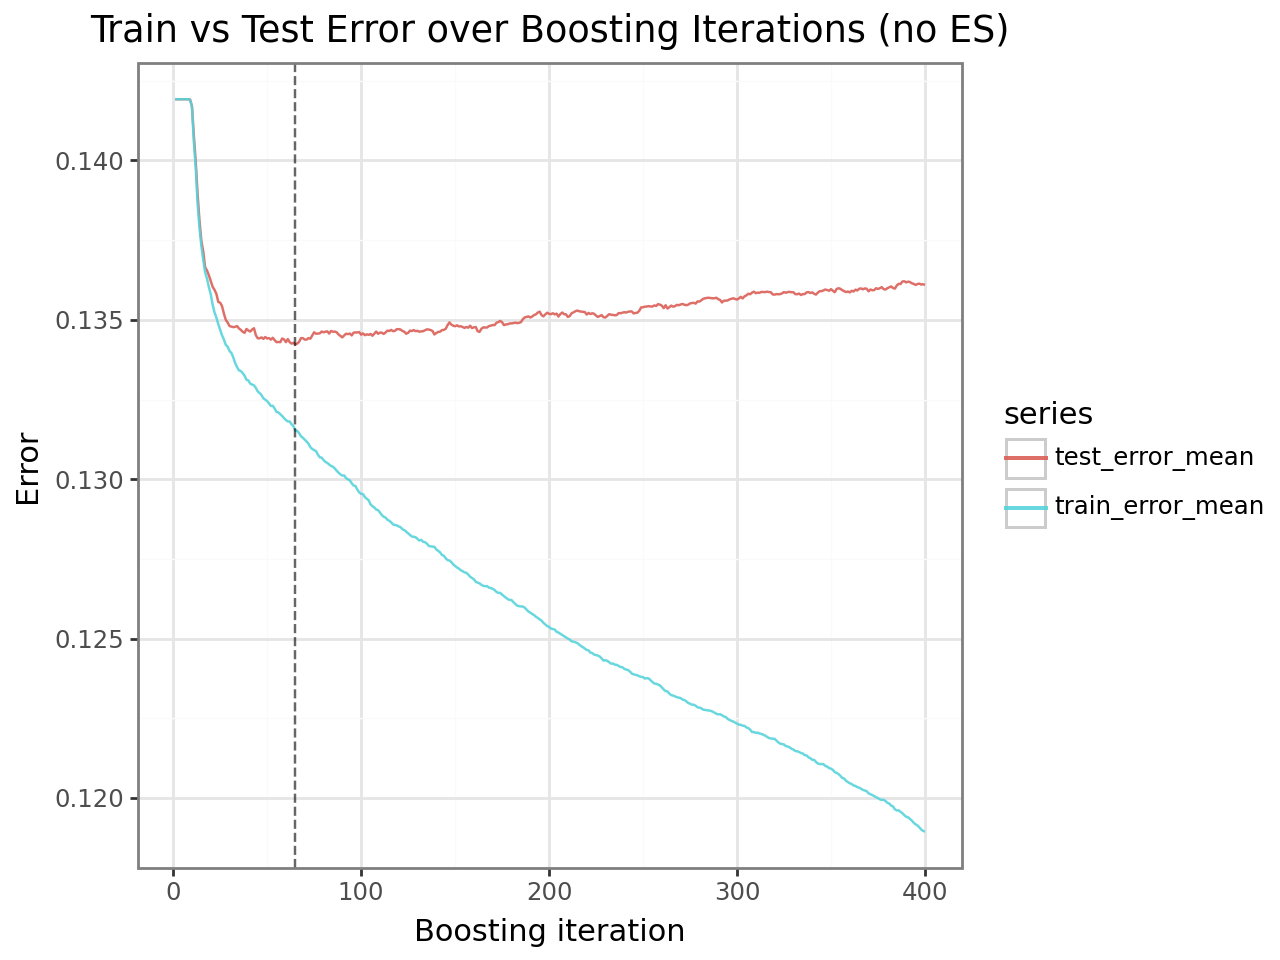

In [ ]:
df_long = df_plot.melt( # Melt data
    id_vars=["iter"],
    value_vars=["train_error_mean", "test_error_mean"],
    var_name="series",
    value_name="err"
)
# Create plot
p_err_both = (
    ggplot(df_long, # Set data
           aes(x="iter", y="err", color="series")) # Set aesthetics
    + geom_line(alpha=0.9) # Set geom line
    + geom_vline(xintercept=best_iter, linetype="dashed", alpha=0.6) # Add vertical line for best iteration
    + theme_bw() # Set theme
    + labs( # Set labels
        title="Train vs Test Error over Boosting Iterations (no ES)",
        x="Boosting iteration",
        y="Error"
    )
)
# Display plot
p_err_both

Train error continued to decrease even though there were no more improvements in the test error.

We tune max_depth and min_child_weight as these are likely to have the largest effect on model outcome. We allow up to 1000 rounds for each configuration and set the early stopping rounds so that each fit stops once the cross-validated score has not improved for 20 rounds, the number of rounds a configuration actually needs is one of the things we want to read off.

In [ ]:
# Set range of parameter values to try
grid = {
    "max_depth": [3,  7, 10],
    "min_child_weight": [ 5, 7, 10],
}
param_grid = list(ParameterGrid(grid))

# Set base model parameters
base_params = {
    "objective": "binary:logistic",
    "eta": 0.10,
    "eval_metric": ["error", "auc"],  # AUC last, so early stopping watches AUC
    "tree_method": "hist",
    "seed": 111111,
}

A function to run our model with the given parameters and return the results:

In [ ]:
def run_one_cv(md, mcw):
    """Run xgb.cv for a single (max_depth, min_child_weight) pair and return best metrics."""
    params = base_params.copy()
    params.update({"max_depth": int(md), "min_child_weight": int(mcw)})

    cv = xgb.cv(
        params=params,
        dtrain=dtrain,              # DMatrix from earlier
        num_boost_round=1000,       # Upper limit - early stopping will cut this short
        nfold=5,                    # 5-fold CV
        early_stopping_rounds=20,   # stop if no improvement
        stratified=True,
        shuffle=True,
        verbose_eval=False,
        seed=111111,
    )

    # Best round is the length of the early-stopped trace
    best_round = len(cv)

    # Read AUC & error at the best round row explicitly
    best_row = cv.iloc[best_round - 1]
    best_err = float(best_row["test-error-mean"])
    best_auc = float(best_row["test-auc-mean"])

    # Return results
    return {
        "max_depth": md,
        "min_child_weight": mcw,
        "best_round": best_round,
        "test_error": best_err,
        "test_auc": best_auc,
    }


Apply this to our dataset:

In [ ]:
# The search: one xgb.cv per (max_depth, min_child_weight) pair
def run_depth_search():
    results = []
    for p in tqdm(param_grid, desc="Grid CV (serial)"):
        results.append(run_one_cv(p["max_depth"], p["min_child_weight"]))
    return pd.DataFrame(results)

# Run and store it
results1 = run_depth_search()

Grid CV (serial): 100%|██████████| 9/9 [04:22<00:00, 29.12s/it]


Join our results into a data frame and identify the best set of parameters. We sort by AUC rather than by the error rate. AUC measures how well the model ranks companies and does not depend on a cut-off at all, which makes it the more informative criterion here:

In [ ]:
# Create and sort results data frame
cv_results1_df = (
    pd.DataFrame(results1)
      .sort_values(["test_auc", "test_error"], ascending=[False, True])
      .reset_index(drop=True)
)
# View all nine configurations, not just the winner
display(cv_results1_df)

# Identify best parameters
best_pair = cv_results1_df.iloc[0].to_dict()
print("Best (by max test_auc, then min test_error):", best_pair)

,max_depth,min_child_weight,best_round,test_error,test_auc
0,3,5,229,0.134564,0.835113
1,3,7,252,0.134535,0.835112
2,3,10,270,0.134403,0.835109
3,7,10,62,0.134873,0.834328
4,7,7,60,0.134644,0.834256
5,7,5,55,0.134575,0.833970
6,10,10,47,0.135326,0.831930
7,10,7,37,0.135269,0.831453
8,10,5,38,0.134936,0.831041


Best (by max test_auc, then min test_error): {'max_depth': 3.0, 'min_child_weight': 5.0, 'best_round': 229.0, 'test_error': 0.13456353193030418, 'test_auc': 0.8351129515452882}


A max depth of 3 and a minimum child weight of 5, with 229 iterations, gave the highest AUC.

What this table tells us confidently is that shallow trees beat deep ones here.

We can also visualize the results of the tuning in a heatmap.

In [ ]:
# Create results data frame
res_db = (
    cv_results1_df[["max_depth", "min_child_weight", "test_auc", "test_error"]]
    .rename(columns={"test_auc": "auc", "test_error": "error"})
    .copy()
)


# Convert to categorical (factor) for plotting axes
res_db["max_depth"] = res_db["max_depth"].astype("category")
res_db["min_child_weight"] = res_db["min_child_weight"].astype("category")


# Compute midpoints for diverging color scales
auc_midpoint = res_db["auc"].mean()
err_midpoint = res_db["error"].mean()

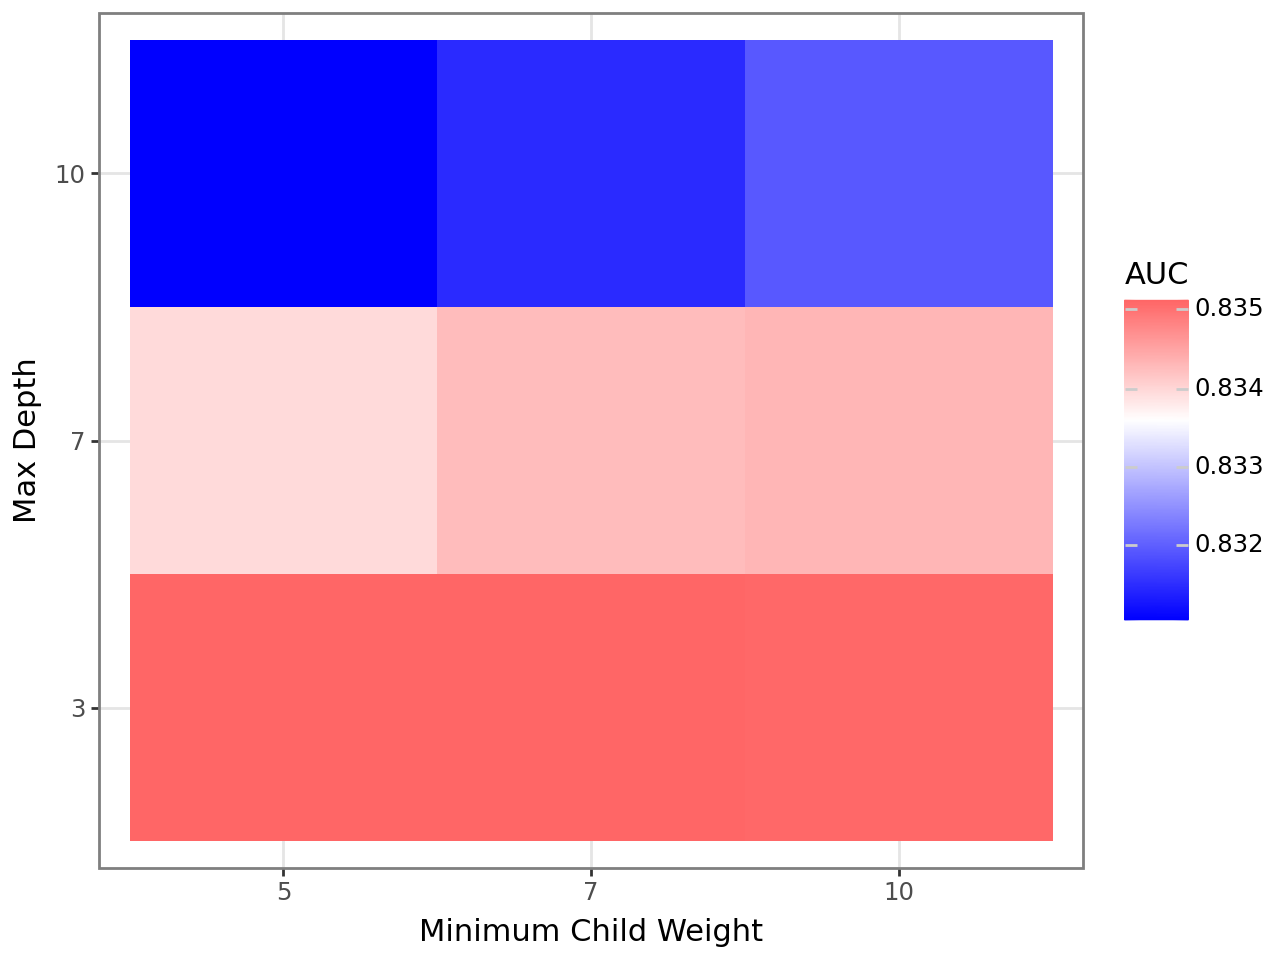

In [ ]:
g_2 = (
    ggplot(res_db, aes(y="max_depth", x="min_child_weight", fill="auc"))  # set aesthetics
    + geom_tile()                                                         # Use geom_tile for heatmap
    + theme_bw()                                                          # Set theme
    + scale_fill_gradient2(
        low="blue", mid="white", high="red",                              # Choose colors
        midpoint=auc_midpoint,                                            # Choose mid point
        na_value="grey",                                                  # Choose NA value

    )
    + labs(x="Minimum Child Weight", y="Max Depth", fill="AUC")           # Set labels
)
g_2

AUC is highest at max depth = 3, lowest at max = depth 10. Shallow trees win.

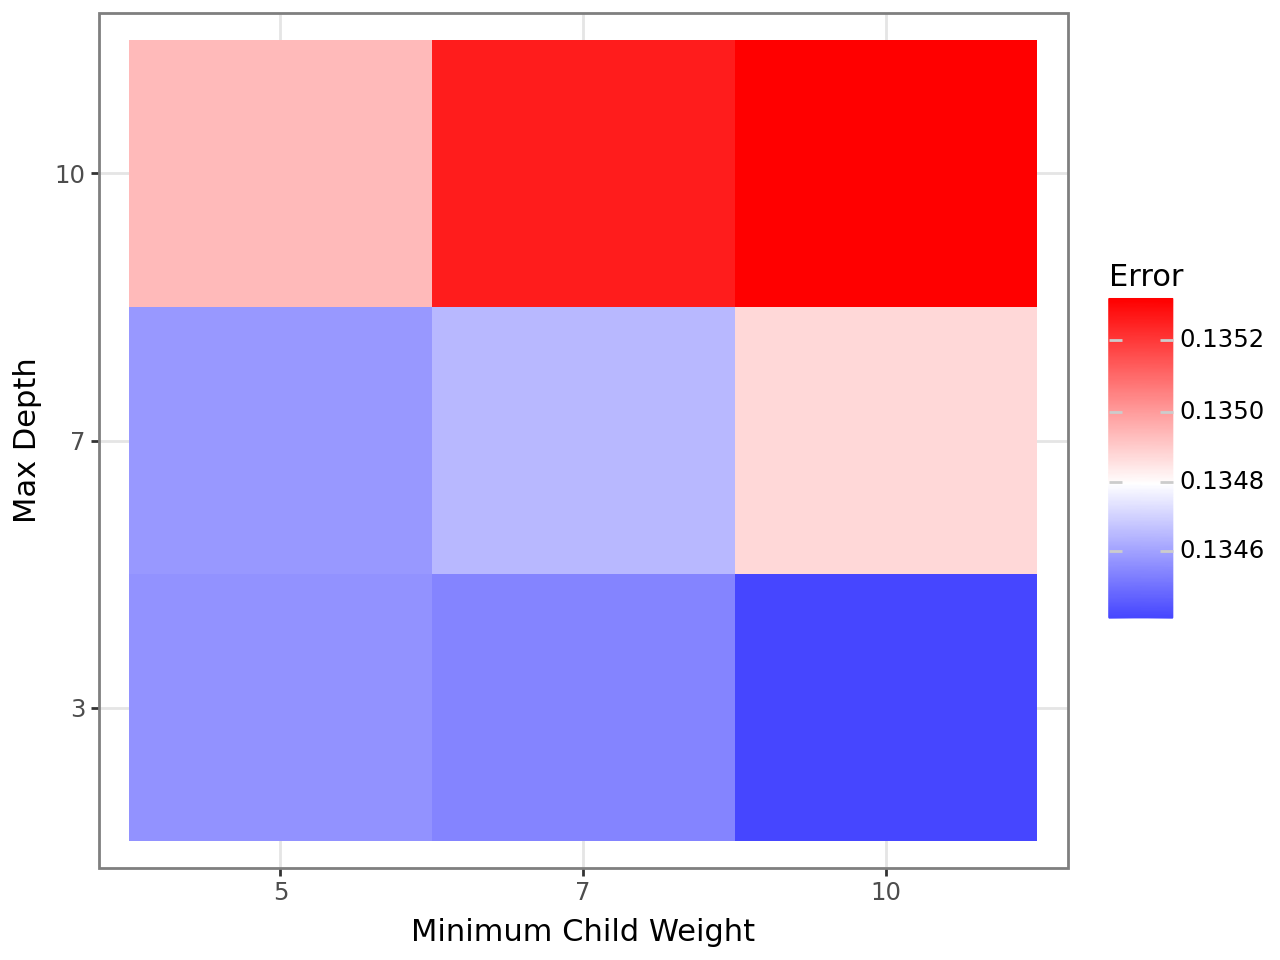

In [ ]:
g_3 = (
    ggplot(res_db, aes(y="max_depth", x="min_child_weight", fill="error"))  # set aesthetics
    + geom_tile()                                                            # Use geom_tile for heatmap
    + theme_bw()                                                             # Set theme
    + scale_fill_gradient2(
        low="blue", mid="white", high="red",                                 # Choose colors
        midpoint=err_midpoint,                                               # Choose mid point
        na_value="grey",                                                     # Choose NA values
    )
    + labs(x="Minimum Child Weight", y="Max Depth", fill="Error")            # Set labels
)
display(g_3)

The heatmaps tell the same story: the depth-3 row is clearly better than the deeper trees.

In [ ]:
tuned_max_depth = int(best_pair['max_depth']) # Extract max depth
tuned_min_child = int(best_pair['min_child_weight']) # Extract min_child_weight

In [ ]:
tuned_max_depth, tuned_min_child

(3, 5)

Stored these variables to use in our final model.

Next we tune gamma, the minimum loss reduction necessary to make a further partition in a node. Gamma is a pruning parameter: a candidate split has to buy at least gamma of loss reduction or it is not made at all.

In [ ]:
# Define gamma grid
gamma_vals = [0.00, 0.50, 1.00, 5.00, 10.00]

# Set base parameters
base_params = {
    "objective": "binary:logistic",
    "eta": 0.10,
    "max_depth": tuned_max_depth, # Uuse tuned value of max depth
    "min_child_weight": tuned_min_child, # Use tuned value of min child weight
    "tree_method": "hist",
    "eval_metric": ["error", "auc"], # AUC last, so early stopping watches AUC
    "seed": 111111,
}

Testing different values and see which leads to the best results:

In [ ]:
# The search: one xgb.cv per gamma value
def run_gamma_search():
    rows = [] # Create data frame to store valus
    for g in tqdm(gamma_vals, desc="Gamma CV (serial)"): # For each gamma value
        params = base_params.copy() # Create copy of base parameters
        params["gamma"] = float(g) # Replace value with current gamma value

        # Run xgb.cv
        cv = xgb.cv(
            params=params,
            dtrain=dtrain,                # Set training data
            num_boost_round=100,          # Set number of rounds
            nfold=5,                      # Set folds for cross validation
            early_stopping_rounds=20,     # Set early stopping rounds
            stratified=True,
            shuffle=True,
            verbose_eval=False,
            seed=111111, #Set seed
        )

        # Best iteration is the length of the early-stopped trace
        best_round = len(cv)
        best_row = cv.iloc[best_round - 1]
        # Store results from current iteration
        rows.append({
            "gamma": g,
            "best_round": int(best_round),
            "test_auc": float(best_row["test-auc-mean"]),
            "test_error": float(best_row["test-error-mean"]),
        })

    # Join results into data frame
    return pd.DataFrame(rows)

gamma_results = run_gamma_search()

# Sort the table and read the winner off it
gamma_results = (gamma_results
                   .sort_values(['test_auc', 'test_error'], ascending=[False, True])
                   .reset_index(drop=True))
# View results
display(gamma_results)
# Extract best value
best_gamma = float(gamma_results.iloc[0]['gamma'])
# Print out vest value
print(f"Selected gamma (by max test_auc, then min test_error): {best_gamma:.2f}")


Gamma CV (serial): 100%|██████████| 5/5 [01:37<00:00, 19.53s/it]


,gamma,best_round,test_auc,test_error
0,0.0,100,0.834260,0.134982
1,0.5,100,0.834260,0.134982
2,1.0,100,0.834257,0.135028
3,5.0,100,0.834115,0.134994
4,10.0,100,0.833652,0.134982


Selected gamma (by max test_auc, then min test_error): 0.00


Gamma is doing very little here. Everything up to 1 gives essentially the same result. In reality this parameter is close to inert for this problem, because with max_depth=3 and min_child_weight=5 we are already refusing to make the marginal splits gamma would prune.

In [ ]:
tuned_gamma = float(best_gamma) # Extract best gamma value

Store gamma for our final model.

We tune the subsample and colsample_bytree parameters. First creating the different values we are going to try and setting our base parameters. A coarse 3 x 3 grid is enough to tell us whether sampling helps at all.

In [ ]:
# Create grid of possible values
grid = {
    "subsample":        [0.6, 0.8, 1.0],
    "colsample_bytree": [0.6, 0.8, 1.0],
}
# Convert into parameter grid and then list
param_grid = list(ParameterGrid(grid))
# Set base parameters
base_params = {
    "objective": "binary:logistic",
    "eta": 0.10,
    "max_depth": tuned_max_depth, # Use tuned value for max depth
    "min_child_weight": tuned_min_child, # Use tuned value for min child weight
    "gamma": tuned_gamma, # Use tuned value for gamma
    "tree_method": "hist",
    "eval_metric": ["error", "auc"], # AUC last, so early stopping watches AUC
    "seed": 111111,
}

 Function to carry out the tuning for us:

In [ ]:
# Create function
def run_one_cv(subsample, colsample_bytree):
    """Run xgb.cv for a single (subsample, colsample_bytree) and return best metrics."""
    params = base_params.copy() # Create copy of base parameters
    params.update({ # Update with values of subsample and colsample_bytree
        "subsample": float(subsample),
        "colsample_bytree": float(colsample_bytree),
    })
    # Run xgb.cv
    cv = xgb.cv(
        params=params,  # Set parameters
        dtrain=dtrain,  # Set training data
        num_boost_round=100, # Set number of rounds
        nfold=5,  # Set cross-validation folds
        early_stopping_rounds=20, # Set number of early stopping rounds
        stratified=True,
        shuffle=True,
        verbose_eval=False,
        seed=111111, # Set seed
    )

    best_round = len(cv)             # early-stopped length
    best_row = cv.iloc[best_round - 1] # Identify best row
    # Return results
    return {
        "subsample": subsample,
        "colsample_bytree": colsample_bytree,
        "best_round": int(best_round),
        "test_auc": float(best_row["test-auc-mean"]),
        "test_error": float(best_row["test-error-mean"]),
    }



Apply to that to the different parameter values we would like to test:

In [ ]:
# The search: one xgb.cv per (subsample, colsample_bytree) pair
def run_sampling_search():
    rows = [] # Create empty list to store results
    # For each set of parameters
    for p in tqdm(param_grid, desc="Subsample x Colsample_bytree CV (serial)"):
        rows.append(run_one_cv(p["subsample"], p["colsample_bytree"])) # Run tuning function and store results
    # Convert results into data frame
    return pd.DataFrame(rows)

# Run it, or load the nine-row table it produced last time
sc_results = run_sampling_search()

# Sort the table and read the winner off it - this happens the same way whether
# the search just ran or the table came from the cache
sc_results = (sc_results
                .sort_values(['test_auc','test_error'], ascending=[False, True])
                .reset_index(drop=True))
# View results
display(sc_results)
# Identify best results
best_sc = sc_results.iloc[0].to_dict()
# Store best results
print(f"Selected subsample={best_sc['subsample']}, "
      f"colsample_bytree={best_sc['colsample_bytree']} "
      f"(max test_auc={best_sc['test_auc']:.6f}, error={best_sc['test_error']:.6f}, "
      f"best_round={best_sc['best_round']})")


Subsample x Colsample_bytree CV (serial): 100%|██████████| 9/9 [02:56<00:00, 19.66s/it]


,subsample,colsample_bytree,best_round,test_auc,test_error
0,0.6,0.8,100,0.834473,0.134644
1,0.6,0.6,100,0.834395,0.134730
2,1.0,0.6,100,0.834332,0.134695
3,0.8,0.8,100,0.834318,0.134455
4,0.6,1.0,100,0.834285,0.134942
5,1.0,1.0,100,0.834260,0.134982
6,0.8,0.6,100,0.834248,0.134449
7,0.8,1.0,100,0.834228,0.134690
8,1.0,0.8,100,0.834116,0.134827


Selected subsample=0.6, colsample_bytree=0.8 (max test_auc=0.834473, error=0.134644, best_round=100.0)


Subsample of 0.6 and a colsample_bytree of 0.8, gives the best AUC, with the nine rows spanning 0.8341 to 0.8344. Subsampling is a way of regularising the model, and with trees this shallow we are not overfitting enough for it to buy us anything. Visualizing:

In [ ]:
# Convert treults table to have simpler names and drop round
res_db = (
    sc_results[["subsample", "colsample_bytree", "test_auc", "test_error"]]
    .rename(columns={
        "colsample_bytree": "colsample_by_tree",
        "test_auc": "auc",
        "test_error": "error"
    })
    .copy()
)

res_db["subsample"] = res_db["subsample"].astype("category")            # Convert tree number to factor for plotting
res_db["colsample_by_tree"] = res_db["colsample_by_tree"].astype("category")  # Convert node size to factor for plotting


auc_midpoint = res_db["auc"].mean() # Calculate mean AUC
err_midpoint = res_db["error"].mean() # Calculate mean Error

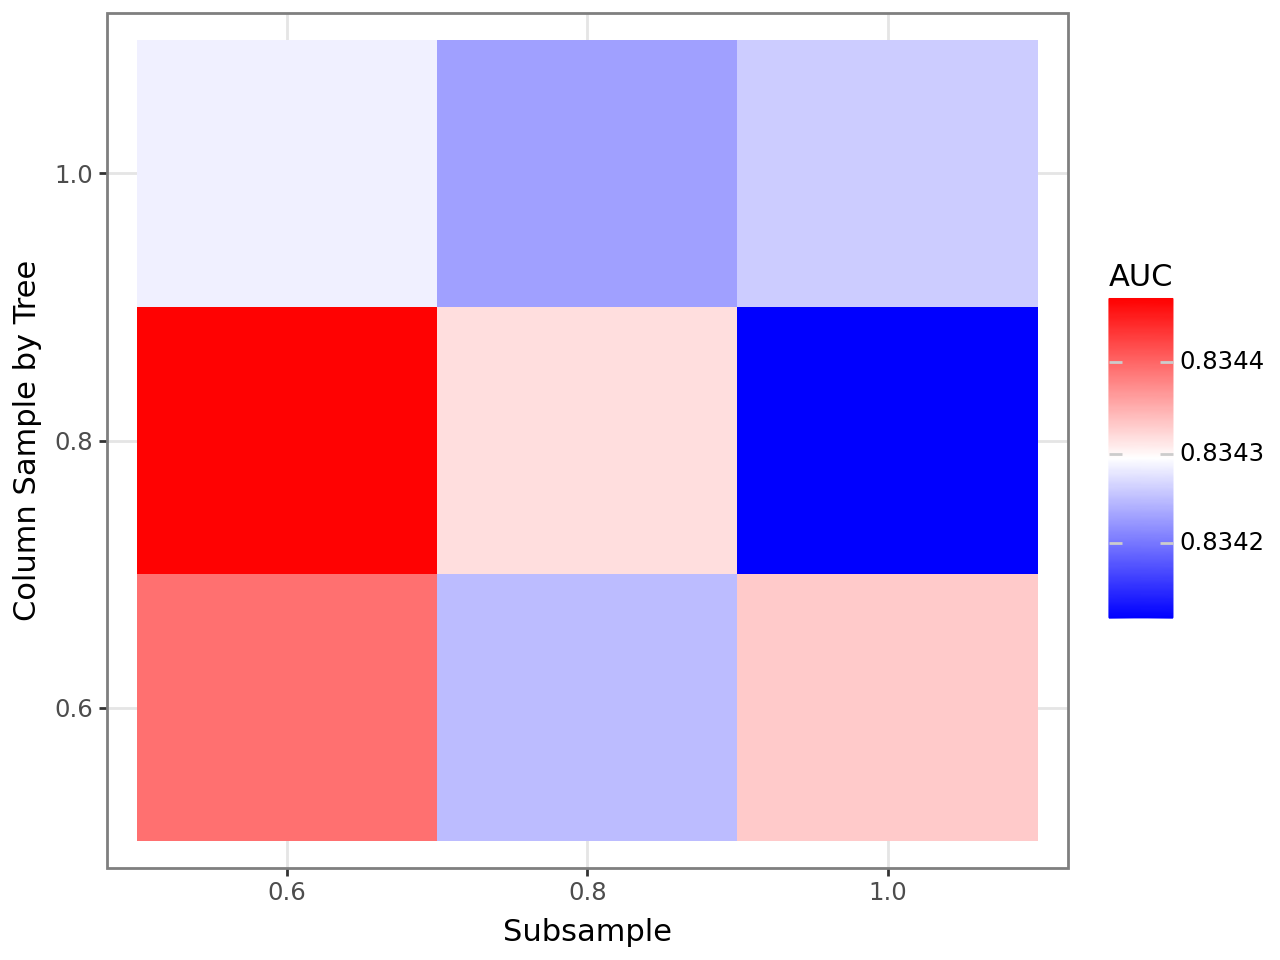

In [ ]:
# Create plot
g_4 = (
    ggplot(res_db, aes(y="colsample_by_tree", x="subsample", fill="auc"))  # set aesthetics
    + geom_tile()                                                          # Use geom_tile for heatmap
    + theme_bw()                                                           # Set theme
    + scale_fill_gradient2(
        low="blue", mid="white", high="red",                               # Choose colors
        midpoint=auc_midpoint,                                             # Choose mid point
        na_value="grey",                                                   # Choose NA value
        guide="colorbar"                                                   # Set color bar (plotnine uses 'colorbar')
    )
    + labs(x="Subsample", y="Column Sample by Tree", fill="AUC")           # Set labels
)
display(g_4)  # Generate plot

Subsample 0.6 and column sample by tree 0.8 give the highest AUC - while subsample 1.0 and column sample by tree 0.8 give the lowest.

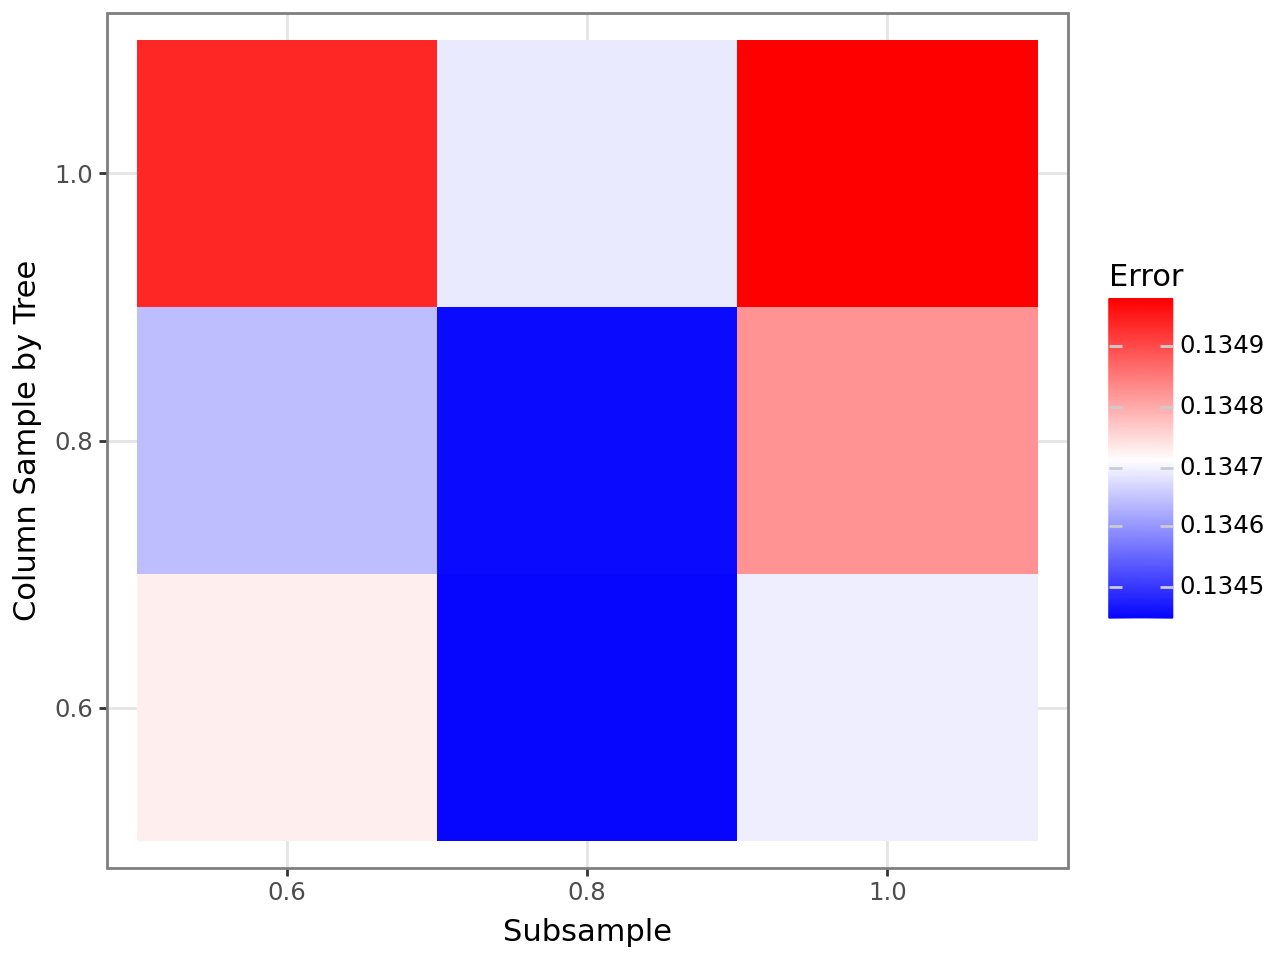

In [ ]:
# Create plot
g_5 = (
    ggplot(res_db, aes(y="colsample_by_tree", x="subsample", fill="error"))  # set aesthetics
    + geom_tile()                                                            # Use geom_tile for heatmap
    + theme_bw()                                                             # Set theme
    + scale_fill_gradient2(
        low="blue", mid="white", high="red",                                 # Choose colors
        midpoint=err_midpoint,                                               # Choose mid point
        na_value="grey",                                                     # Choose NA value
        guide="colorbar"                                                     # Set color bar
    )
    + labs(x="Subsample", y="Column Sample by Tree", fill="Error")           # Set labels
)
display(g_5)  # Generate plot

Error lowest at subsample 0.8.

In [ ]:
tuned_subsample = float(best_sc['subsample']) # Extract best subsample
tuned_colsample = float(best_sc['colsample_bytree']) # Extract best colsample_bytree
tuned_subsample, tuned_colsample


(0.6, 0.8)

Saved the variables for the final model.

The final step in our tuning process is to lower the learning rate (eta) and add more trees, We also want to visualize the performance of the model over the iterations:

In [ ]:
# Set ETA values to try
etas = [0.3, 0.1, 0.05, 0.01, 0.005]
# Set base parameters
base_params = {
    "objective": "binary:logistic",
    "eval_metric": ["error", "auc"], # AUC last, so early stopping watches AUC
    "max_depth": tuned_max_depth, # Use tuned value for max depth
    "min_child_weight": tuned_min_child, # Use tuned value for min_child_weight
    "gamma": tuned_gamma, # Use tuned value for gamma
    "subsample": tuned_subsample, # Use tuned value for subsample
    "colsample_bytree": tuned_colsample, # Use tuned value for colsample_bytree
    "tree_method": "hist",
    "seed": 111111,
}

Loop through:

In [ ]:
# The search: one xgb.cv per learning rate, keeping the whole per-iteration trace
def run_eta_search():
    curves = []     # per-iteration logs for plotting
    # For each learning rate
    for eta in tqdm(etas, desc="Learning-rate CV (serial)"):
        params = base_params.copy() # Create copy of parmameters
        params["eta"] = float(eta) # Update ETA value
        # Apply xgb.cv
        cv = xgb.cv(
            params=params, # Set parameters
            dtrain=dtrain, # Set training data
            num_boost_round=1000,  # run to 1000 unless ES stops early
            nfold=5, # Set folds for cross validation
            early_stopping_rounds=100, # Set early stopping rounds
            stratified=True,
            shuffle=True,
            verbose_eval=False,
            seed=111111,
        )

        # Extract data for model performance
        df_log = cv.reset_index().rename(columns={"index": "iter"})
        df_log["iter"] = df_log["iter"] + 1 # Increment iterations to get real number
        # fix hyphenated column names for plotnine
        df_log = df_log.rename(columns=lambda c: c.replace("-", "_"))
        df_log["eta"] = str(eta) # Store ETA value as a string
        curves.append(df_log) # Add values to data store

    # Combine curve data
    return pd.concat(curves, ignore_index=True)

# Run it
curves_df = run_eta_search()
curves_df["eta"] = curves_df["eta"].astype(str)  # eta is a label here, not a number

# Each trace was stopped early at its own best round, so the last row of each
# eta's curve IS that eta's best round - which is all the summary table needs
summaries = []
for eta, one_curve in curves_df.groupby("eta", sort=False):
    best_row = one_curve.iloc[-1]                    # Identify best row
    summaries.append({"eta": float(eta),
                      "best_round": int(best_row["iter"]),
                      "test_error": float(best_row["test_error_mean"]),  # Extract best error value
                      "test_auc": float(best_row["test_auc_mean"])})     # Extract best AUC value

# Create data frame of result data
summ_df = pd.DataFrame(summaries).sort_values(
    ["test_auc","test_error"] ,
    ascending=[False, True]
).reset_index(drop=True)

display(summ_df)


Learning-rate CV (serial): 100%|██████████| 5/5 [10:53<00:00, 130.75s/it]


,eta,best_round,test_error,test_auc
0,0.050,623,0.134317,0.835559
1,0.100,257,0.134323,0.835386
2,0.010,1000,0.134678,0.834673
3,0.300,117,0.134627,0.834355
4,0.005,1000,0.135028,0.832444


Lowest error and largest AUC with eta = 0.05

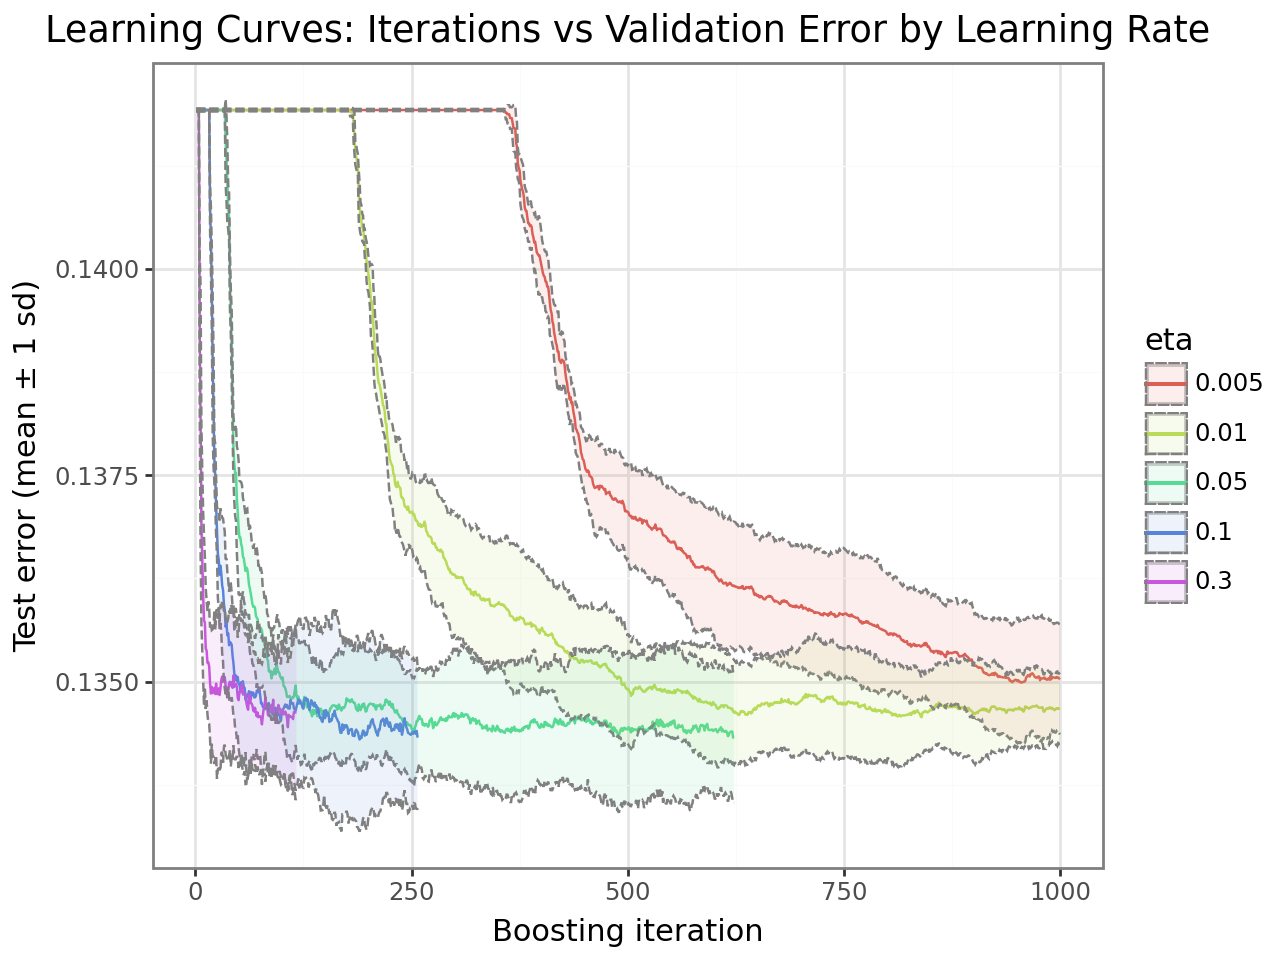

In [ ]:
# Precompute ribbons (mean ± 1 sd) per-eta
curves_df["y_lower"] = curves_df["test_error_mean"] - curves_df["test_error_std"]
curves_df["y_upper"] = curves_df["test_error_mean"] + curves_df["test_error_std"]

# Create plot
p_lr = (
    ggplot(curves_df,  # Set dataset
           aes(x="iter", y="test_error_mean", color="eta", group="eta")) # Set Aesthetics
    + geom_line() # Set geom line
    + geom_ribbon(aes(ymin="y_lower", ymax="y_upper", fill="eta"), linetype="dashed", alpha=0.1, color="grey") # Add error bars
    + theme_bw() # Set theme
    + labs( # Set labels
        title="Learning Curves: Iterations vs Validation Error by Learning Rate",
        x="Boosting iteration",
        y=("Test error (mean ± 1 sd)" ),
        color="eta", fill="eta"
    )
)
# Display plot
display(p_lr)



For a high learning rate, 0.3, error drops very fast in the first few boosting iterations but then begins to increase - hence overfitting early - doing it too aggresively.

For a low learning rate, like 0.005 or 0.01, error goes down slowly and needs thousands of iterations to get to its minimum, so its very heavy computationally and we can't even see convergence within the selected limit.

Here eta = 0.05 is perfect, it converges to the lowest test error and highest AUC at 623 iterations.

In [ ]:
best_eta = float(summ_df.iloc[0]["eta"]) # Extract best learning rate
best_round = int(summ_df.iloc[0]["best_round"]) # Extract best round
print(f"Selected eta={best_eta} with best_round={best_round}, " # Print results
      f"test_error={summ_df.iloc[0]['test_error']:.6f}, "
      f"AUC={summ_df.iloc[0]['test_auc']:.6f}")

Selected eta=0.05 with best_round=623, test_error=0.134317, AUC=0.835559


In [ ]:
tuned_eta = float(best_eta) # Extract best learning rate

Store the tuned eta variable.

In [ ]:
# these are the values the search above selected for us.
# Uncomment if you have skipped the tuning cells and want to go straight to the final model.
# tuned_max_depth = 3
# tuned_min_child = 5
# tuned_gamma     = 0.0
# tuned_subsample = 0.6
# tuned_colsample = 0.8
# tuned_eta       = 0.05

Fitting our final tuned XGB model with the selected parameters.

In [ ]:
params = {
    "objective": "binary:logistic",
    "eval_metric": ["auc", "error"],
    "max_depth": tuned_max_depth, # Use tuned value for max depth
    "min_child_weight": tuned_min_child, # Use tuned value for min_child_weight
    "gamma": tuned_gamma, # Use tuned value for gamma
    "subsample": tuned_subsample, # Use tuned value for subsample
    "colsample_bytree": tuned_colsample, # Use tuned value for colsample_bytree
    "eta": tuned_eta, # Use tuned value for eta
    "tree_method": "hist",
    "seed": 111111,
}

# Number of rounds for both of the final models - taken from the learning rate search
n_final = best_round
# Set up XGBoost
watchlist = [(dtrain, "train")] # Set data for evaluation
# Apply model
xgb_tuned = xgb.train(params, # Set parameters
                    dtrain,  # Set training data
                    num_boost_round=n_final, # Set number of rounds to the best round from tuning
                    evals=watchlist,  # Set data to evaluate on
                    verbose_eval=50) # Set print out frequency

[0]	train-auc:0.78122	train-error:0.14192
[50]	train-auc:0.82781	train-error:0.13665
[100]	train-auc:0.83368	train-error:0.13476
[150]	train-auc:0.83559	train-error:0.13424
[200]	train-auc:0.83658	train-error:0.13406
[250]	train-auc:0.83725	train-error:0.13381
[300]	train-auc:0.83782	train-error:0.13363
[350]	train-auc:0.83827	train-error:0.13340
[400]	train-auc:0.83867	train-error:0.13308
[450]	train-auc:0.83905	train-error:0.13295
[500]	train-auc:0.83937	train-error:0.13289
[550]	train-auc:0.83967	train-error:0.13291
[600]	train-auc:0.83995	train-error:0.13281
[622]	train-auc:0.84006	train-error:0.13280


Apply our model to the test set to check its performance:


Confusion matrix:


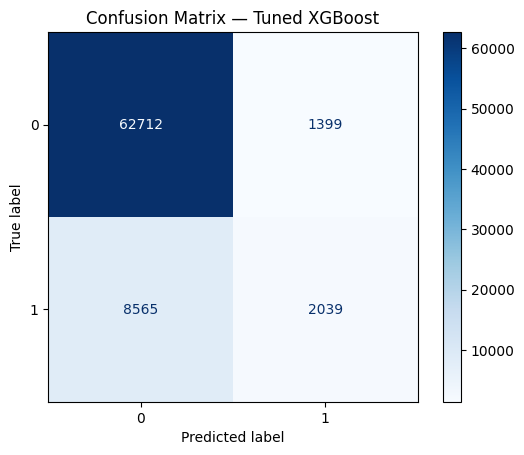


Accuracy):
0.8666398982801312


In [ ]:
test_pred_tuned = xgb_tuned.predict(dtest) # Create predictions


# Convert predictions into classes at 0.5
test_pred_cls_t = (test_pred_tuned >= 0.5).astype(int)


print("\nConfusion matrix:")
cm = (confusion_matrix(y_test, test_pred_cls_t))
disp = ConfusionMatrixDisplay(confusion_matrix=cm)# Set class labels
disp.plot(cmap="Blues") # Set color map
plt.title("Confusion Matrix — Tuned XGBoost") # Set title
plt.show() # Display plot
print("\nAccuracy):")
print(accuracy_score(y_test, test_pred_cls_t)) # Get Accuracy

Accuracy went up to 86.7% (1.1% more compared to the raw model. While it might take some time computationally, we are getting more correct predictions. Still, the issue of low sensitivity (recall) is still present. This is an issue in medical diagnosis models, since we aim to minimize false negatives (we don't want diabetes diagnosis to be missed). So even though accuracy might go up, sensitivity turns out to be a much bigger issue at hand.

### Handling imbalanced data

The low sensitivity comes from the huge class imbalance, and we aim to fix it by scaling the weights for each of the samples.

In [ ]:
# Count values
counts = pd.Series(y_train).value_counts().sort_index()
neg = int(counts.get(0, 0)); pos = int(counts.get(1, 0)) # Calculate positive and negative samples
print(f"Number of negative samples: {neg}")
print(f"Number of positive samples: {pos}")

Number of negative samples: 149592
Number of positive samples: 24742


make a weight by dividing the number of negative samples by the number of positive:

In [ ]:
# Calculate ratio
ratio = neg / pos
# Set ratio as weight for positive samples
w_tr = np.where(y_train == 1, ratio, 1.0).astype(np.float32)
# View weight vector
w_tr

array([1., 1., 1., ..., 1., 1., 1.], dtype=float32)

We use this weight vector when building the dtrain object:

In [ ]:
# Build weighted DMatrices
dtrain_w = xgb.DMatrix(X_train, label=y_train, weight=w_tr)

We fit our model:

In [ ]:
watchlist = [(dtrain_w, "train")] # Set data for evaluation
xgb_w = xgb.train(params, # Set parameters
                    dtrain_w,  # Set training data
                    num_boost_round=n_final, # Set number of rounds - the same as the tuned model, so the comparison is like for like
                    evals=watchlist,  # Set data to evaluate on
                    verbose_eval=50) # Set print out frequency

[0]	train-auc:0.78263	train-error:0.27738
[50]	train-auc:0.82814	train-error:0.24953
[100]	train-auc:0.83408	train-error:0.24542
[150]	train-auc:0.83584	train-error:0.24339
[200]	train-auc:0.83675	train-error:0.24231
[250]	train-auc:0.83736	train-error:0.24187
[300]	train-auc:0.83797	train-error:0.24156
[350]	train-auc:0.83844	train-error:0.24116
[400]	train-auc:0.83889	train-error:0.24077
[450]	train-auc:0.83924	train-error:0.24018
[500]	train-auc:0.83959	train-error:0.23998
[550]	train-auc:0.83988	train-error:0.23987
[600]	train-auc:0.84020	train-error:0.23977
[622]	train-auc:0.84032	train-error:0.23971



Confusion matrix:


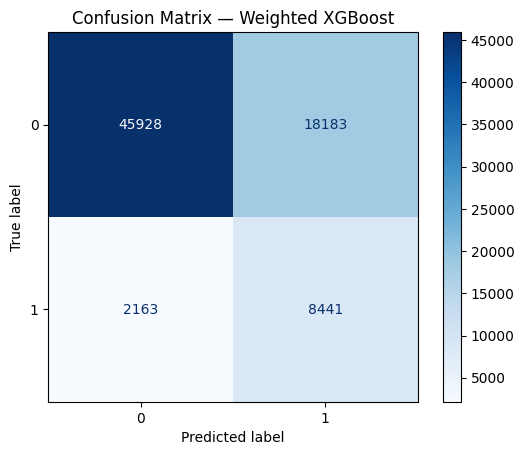


Accuracy):
0.7276852037743425


In [ ]:
test_pred_w = xgb_w.predict(dtest) # Create predictions


# Convert predictions into classes at 0.5
test_pred_cls_w = (test_pred_w >= 0.5).astype(int)


print("\nConfusion matrix:")
cm = (confusion_matrix(y_test, test_pred_cls_w))
disp = ConfusionMatrixDisplay(confusion_matrix=cm)# Set class labels
disp.plot(cmap="Blues") # Set color map
plt.title("Confusion Matrix — Weighted XGBoost") # Set title
plt.show() # Display plot
print("\nAccuracy):")
print(accuracy_score(y_test, test_pred_cls_w)) # Get Accuracy

Accuracy went down, more than 10 percentage points, compared to the raw and tuned XGB models. Regardless, we got to increase the sensitivity by a lot, which for us, is more valuable. More on that in the comparison below:

## Comparison of raw, tuned, and weighted XGB models

In [ ]:
#RAW
tn, fp, fn, tp = confusion_matrix(y_test, test_pred_cls).ravel()
sens = tp / (tp + fn) * 100
spec = tn / (tn + fp) * 100
prec = tp / (tp + fp) * 100
acc = (tp + tn) / (tp + tn + fp + fn) * 100
print(f"Accuracy: {acc:.2f}%")
print(f"Sensitivity (Recall): {sens:.2f}%")
print(f"Specificity: {spec:.2f}%")
print(f"Precision: {prec:.2f}%")

Accuracy: 85.62%
Sensitivity (Recall): 22.33%
Specificity: 96.09%
Precision: 48.59%


In [ ]:
#TUNED
tn, fp, fn, tp = confusion_matrix(y_test, test_pred_cls_t).ravel()
sens = tp / (tp + fn) * 100
spec = tn / (tn + fp) * 100
prec = tp / (tp + fp) * 100
acc = (tp + tn) / (tp + tn + fp + fn) * 100
print(f"Accuracy: {acc:.2f}%")
print(f"Sensitivity (Recall): {sens:.2f}%")
print(f"Specificity: {spec:.2f}%")
print(f"Precision: {prec:.2f}%")

Accuracy: 86.66%
Sensitivity (Recall): 19.23%
Specificity: 97.82%
Precision: 59.31%


In [ ]:
#WEIGHTED
tn, fp, fn, tp = confusion_matrix(y_test, test_pred_cls_w).ravel()
sens = tp / (tp + fn) * 100
spec = tn / (tn + fp) * 100
prec = tp / (tp + fp) * 100
acc = (tp + tn) / (tp + tn + fp + fn) * 100
print(f"Accuracy: {acc:.2f}%")
print(f"Sensitivity (Recall): {sens:.2f}%")
print(f"Specificity: {spec:.2f}%")
print(f"Precision: {prec:.2f}%")

Accuracy: 72.77%
Sensitivity (Recall): 79.60%
Specificity: 71.64%
Precision: 31.70%


For the raw and tuned models, both have high accuracy and specificity, because of the imbalanced nature of this dataset - so these models are predicting Diabetes = 0 most of the time, giving the horrible sensitivity of approx. 20%. By using the class weights to balance the loss function, the model is penalized for the missed positive cases. The big trade-off was accuracy for sensitivity. For the weighted model, sensitivity increased to almost 80%! almost 60 percentage points more compared to the other models. Overall accuracy dropped because it flagged more healthy people as diabetic, which in a medical diagnosis perspective, is not as bad as entirely missing diabetic people and classifying them as non diabetic.

For our use case (medical screening purposes), the weighted model should be the one deployed because failing to diagnose diabetes is more dangerous than a false alarm, that could be cleared up by a subsequent medical visit. The purpose of this model is an initial screening, complemented by real medical expertise.

## ROC

Compare the performance of our models using ROC curves and calculate the AUC:

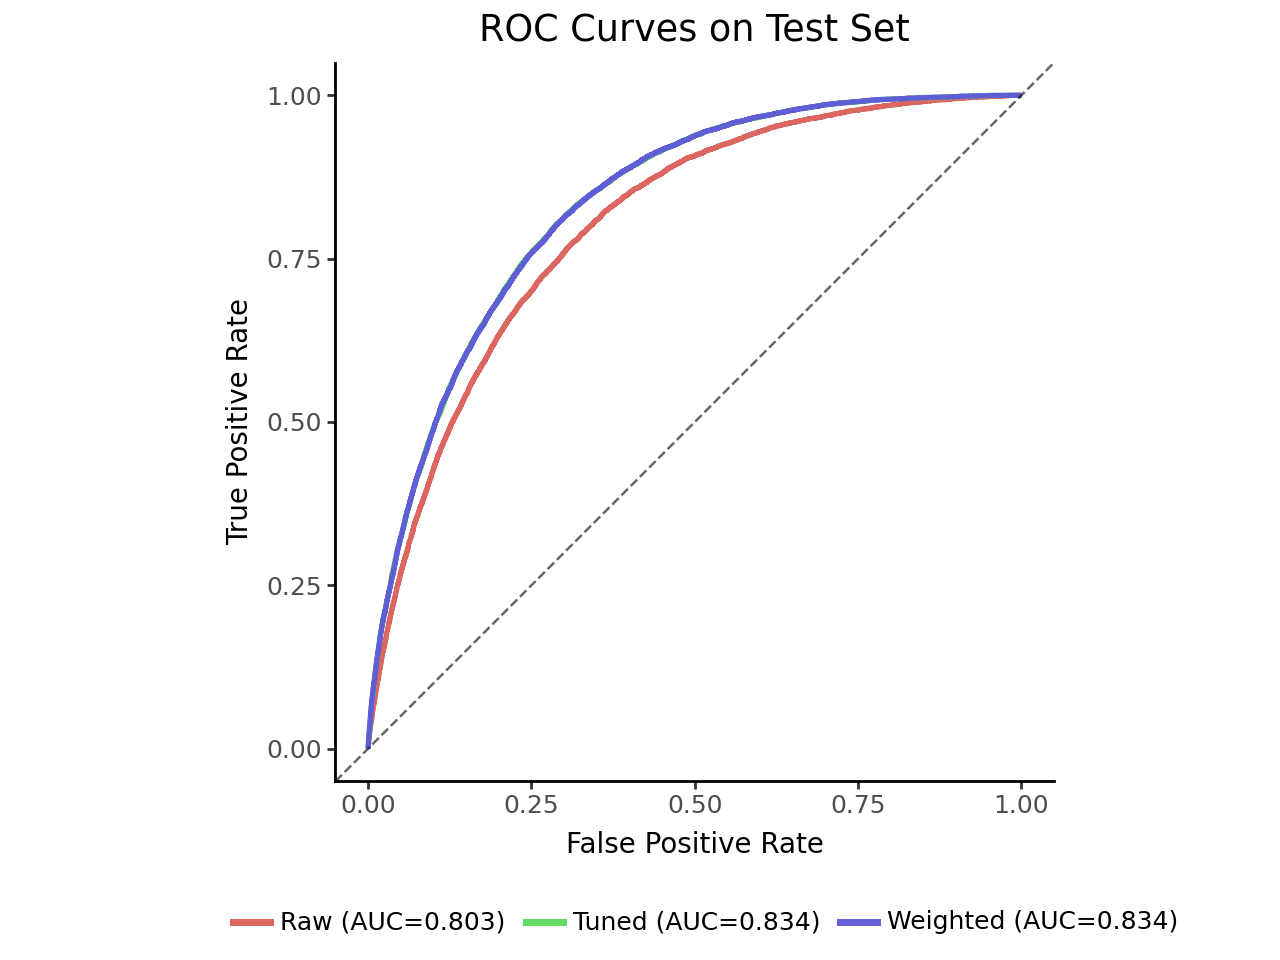

In [ ]:
# Create data frame of predictions
pred_dict = {}
pred_dict['Raw']      = np.asarray(test_pred_raw).ravel()
pred_dict['Tuned']    = np.asarray(test_pred_tuned).ravel()
pred_dict['Weighted'] = np.asarray(test_pred_w).ravel()


# Build ROC curves & AUCs
curves = [] # Create empty files to store results
aucs = {}
# For each set of predictions
for name, preds in pred_dict.items():
    fpr, tpr, _ = roc_curve(y_test, preds) # Calculate ROC
    auc_val = roc_auc_score(y_test, preds) # Calculate AUC
    aucs[name] = auc_val # Store AUC
    curves.append(pd.DataFrame({"fpr": fpr, "tpr": tpr, "Model": name})) # Store ROC

# Joine results to data frame
df_curves = pd.concat(curves, ignore_index=True)
# Put AUC in the legend label
df_curves["Label"] = df_curves["Model"].map(lambda m: f"{m} (AUC={aucs[m]:.3f})")

# Create plot
p_roc = (
    ggplot(df_curves,  # Set data frame
           aes(x="fpr", y="tpr", color="Label")) # Set aesthetics
    + geom_line(size=1.05, alpha=0.95) # Set geom_line
    + geom_abline(intercept=0, slope=1, linetype="dashed", alpha=0.6) # Set 45 degree line
    + coord_equal()
    + theme_classic()
    + theme(
        legend_position="bottom",
        legend_title=element_text(size=9),
        legend_text=element_text(size=9),
        axis_text=element_text(size=9),
        axis_title=element_text(size=10)
    )
    + labs( # Set labels
        title="ROC Curves on Test Set",
        x="False Positive Rate",
        y="True Positive Rate",
        color=""  # hide legend title
    )
)
# Generate plot
p_roc



## Variable Importance

Now we can extract the different importance values from our model:

In [ ]:
# Extract importance by different definitions
imp_gain       = xgb_tuned.get_score(importance_type='gain')        # Average gain when used
imp_weight     = xgb_tuned.get_score(importance_type='weight')      # Number of times used in splits
imp_cover      = xgb_tuned.get_score(importance_type='cover')       # Average coverage of splits
imp_total_gain = xgb_tuned.get_score(importance_type='total_gain')  # Sum of gain across splits
imp_total_cov  = xgb_tuned.get_score(importance_type='total_cover') # Sum of coverage across splits

# Convert to tidy DataFrame and join all importance types
def to_df(d, kind):
    if not d:
        return pd.DataFrame(columns=['feature','kind','value'])
    df = (pd.Series(d).rename_axis('feature')
                      .reset_index(name='value'))
    df['kind'] = kind
    return df

# Join data
imp_long = pd.concat([
    to_df(imp_gain, 'gain'),
    to_df(imp_weight, 'weight'),
    to_df(imp_cover, 'cover'),
    to_df(imp_total_gain, 'total_gain'),
    to_df(imp_total_cov, 'total_cover'),
], ignore_index=True)

# View imp_gain
imp_gain

{'HighBP': 456.92523193359375,
 'HighChol': 103.7137451171875,
 'CholCheck': 27.92969512939453,
 'BMI': 43.668243408203125,
 'Smoker': 5.017278671264648,
 'Stroke': 8.403824806213379,
 'HeartDiseaseorAttack': 40.08853530883789,
 'PhysActivity': 5.830707550048828,
 'Fruits': 5.6956377029418945,
 'Veggies': 4.7516961097717285,
 'HvyAlcoholConsump': 37.08570098876953,
 'AnyHealthcare': 4.23262882232666,
 'NoDocbcCost': 3.9420523643493652,
 'GenHlth': 129.03871154785156,
 'MentHlth': 4.729454040527344,
 'PhysHlth': 4.862406253814697,
 'DiffWalk': 52.726375579833984,
 'Sex': 16.248811721801758,
 'Age': 40.7503547668457,
 'Education': 6.2454705238342285,
 'Income': 14.438041687011719}

In [ ]:
# Rank the features by total_gain: loss reduction summed over every split that used the feature
imp_wide = (imp_long # Create data frame in wide form
            .pivot_table(index='feature', columns='kind', values='value', aggfunc='first')
            .reset_index())
# Sort and display values
imp_wide.sort_values('total_gain', ascending=False).head()

kind,feature,cover,gain,total_cover,total_gain,weight
7,GenHlth,4412.999512,129.038712,2.140305e+06,62583.777344,485.0
9,HighBP,4503.125488,456.925232,6.079219e+05,61684.906250,135.0
2,BMI,5261.727539,43.668243,4.093624e+06,33973.894531,778.0
0,Age,4828.830566,40.750355,2.829695e+06,23879.707031,586.0
10,HighChol,3943.768799,103.713745,5.915653e+05,15557.061523,150.0


* weight (a.k.a. frequency) - How many times a feature is chosen to split across all trees.
• High = model often reaches for this feature, but not necessarily for big improvements each time.

* gain (average gain) - The average improvement in the training objective (e.g., logloss) when the feature is used for a split.
• High = whenever this feature is used, it is good at separating the samples

* cover (average coverage) - How many training examples (technically, sum of Hessians) are affected by splits using this feature, on average.
• High = the feature’s splits tend to act on large portions of the data (broad influence).

* total_gain - Sum of gains over all splits that use the feature (≈ gain × weight).
• High = either used a lot, or used a few times with very large improvements (or both).

* total_cover - Sum of cover over all splits that use the feature (≈ cover × weight).
• High = the feature influences a large number of examples across the whole model.


We now get our data into the right format for visualizing the data.

In [ ]:
# Extract top 15 features by total gain
top15_feats = (imp_wide.sort_values('total_gain', ascending=False)
                        .head(15)['feature'].tolist())
# View top 15 features
top15_feats

['GenHlth',
 'HighBP',
 'BMI',
 'Age',
 'HighChol',
 'DiffWalk',
 'Income',
 'HeartDiseaseorAttack',
 'HvyAlcoholConsump',
 'CholCheck',
 'Sex',
 'Education',
 'PhysHlth',
 'MentHlth',
 'Stroke']

In [ ]:
# Convert to long form for plotting
plot_long = imp_long[imp_long['kind'].isin(['weight','gain','total_gain','total_cover'])].copy()
# Extract top 15
plot_long = plot_long[plot_long['feature'].isin(top15_feats)].copy()
# View results
plot_long

,feature,value,kind
0,HighBP,4.569252e+02,gain
1,HighChol,1.037137e+02,gain
2,CholCheck,2.792970e+01,gain
3,BMI,4.366824e+01,gain
5,Stroke,8.403825e+00,gain
6,HeartDiseaseorAttack,4.008854e+01,gain
10,HvyAlcoholConsump,3.708570e+01,gain
13,GenHlth,1.290387e+02,gain
14,MentHlth,4.729454e+00,gain
15,PhysHlth,4.862406e+00,gain


In [ ]:
# Order features by total_gain so all facets share a sensible order
order = (imp_wide.set_index('feature').loc[top15_feats, 'total_gain']
                .sort_values(ascending=True).index.tolist())  # ascending for nice top-down after coord_flip
plot_long['feature'] = pd.Categorical(plot_long['feature'], categories=order, ordered=True)

In [ ]:
# Convert data to long form for plotting
plot_long['metric'] = plot_long['kind'].map({
    'weight': 'Weight (split count)',
    'gain': 'Gain (average per split)',
    'total_gain': 'Total Gain',
    'total_cover': 'Total Cover'
}).fillna(plot_long['kind'])
# Convert feature to categorical
plot_long['feature'] = plot_long['feature'].astype('category')
# View data
plot_long.head()

,feature,value,kind,metric
0,HighBP,456.925232,gain,Gain (average per split)
1,HighChol,103.713745,gain,Gain (average per split)
2,CholCheck,27.929695,gain,Gain (average per split)
3,BMI,43.668243,gain,Gain (average per split)
5,Stroke,8.403825,gain,Gain (average per split)


Visualizing the results:

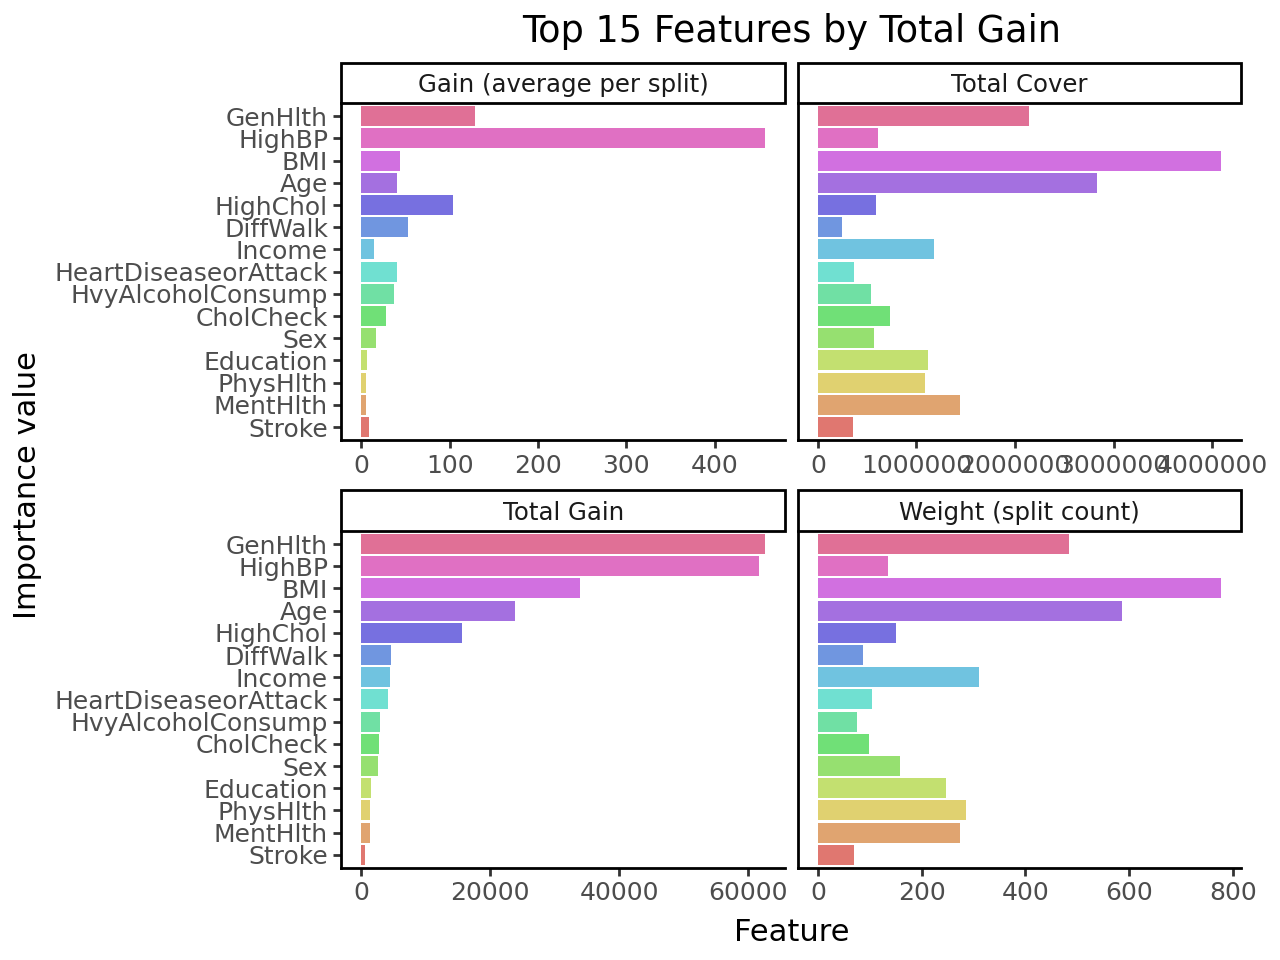

In [ ]:
p_imp = (
    ggplot(plot_long, aes(y='value', x='feature', fill='feature'))   # set aesthetics
    + geom_col(alpha=0.85)                                           # bars
    + coord_flip()                                                   # horizontal bars
    + facet_wrap('~metric', scales='free_x', ncol=2)                 # panels
    + scale_fill_hue()
    + theme_classic()                                                # removes background grid
    + theme(
        legend_position='none',                                      # hide color legend
        axis_text_y=element_text(size=9),                            # improve y labels
        axis_text_x=element_text(size=9)                             # tidy x labels
    )
    + labs(
        title='Top 15 Features by Total Gain',
        x='Importance value',
        y='Feature'
    )
)
display(p_imp)

General Health and High Blood Pressure dominates Total Gain, meaning that they are the most influential in lowering the training loss in the model.

High Blood Pressure has the highest Gain, average gain per split, while it may not be used in many splits as other variables, when the model does choose to split on this variable, it is very powerful.

For weight (split count), BMI and Age have the highest frequency. This makes sense because they are continuous with many unique values.

For Total Cover, BMI, Age, and General Health dominate - splits that do involve these variables happen toward the top of the trees - so they influence big subgroups of the data.

Does the variable help us generalize?

Everything above, weight, gain, cover, is measured on the training data, from the trees we fitted. A variable scores highly there if it helped the model fit rows it has already seen.

Permutation importance asks a different and usually more useful question. Take the fitted model, shuffle one column of the test set so that variable becomes noise, and measure how much test AUC we lose. If the model was genuinely using that variable to generalise, the score falls. If it was using it to memorise the training data, shuffling it may cost nothing at all.

In [ ]:
# Permutation importance on the TEST set: how much AUC do we lose when we shuffle one column?

# permutation_importance expects an sklearn-style model, so we wrap our booster
class BoosterWrapper:
    def __init__(self, booster):
        self.booster = booster
    def fit(self, X, y=None): # Already fitted - this is here so sklearn accepts the object
        return self

# Score a (possibly shuffled) dataset with our booster
def auc_scorer(model, X, y):
    return roc_auc_score(y, model.booster.predict(xgb.DMatrix(X)))

# Shuffle each column 5 times and record the average drop in test AUC
perm = permutation_importance(
    BoosterWrapper(xgb_tuned), # Set model
    X_test,                    # Set data - the TEST set, not the training set
    np.asarray(y_test),        # Set response
    scoring=auc_scorer,        # Set scoring function
    n_repeats=5,               # Number of shuffles per variable
    random_state=111111,       # Set seed
)

# Join results into a data frame
perm_df = (pd.DataFrame({"feature": X_test.columns,
                         "auc_drop": perm.importances_mean,
                         "sd": perm.importances_std})
             .sort_values("auc_drop", ascending=False)
             .reset_index(drop=True))
# View the top 15
perm_df.head(15)

,feature,auc_drop,sd
0,GenHlth,0.050484,0.000930
1,BMI,0.037141,0.000926
2,Age,0.032317,0.000649
3,HighBP,0.016429,0.000410
4,HighChol,0.011556,0.000466
5,CholCheck,0.005475,0.000519
6,HvyAlcoholConsump,0.003744,0.000269
7,Income,0.003243,0.000133
8,Sex,0.003101,0.000226
9,HeartDiseaseorAttack,0.001748,0.000125


In [ ]:
# Create TreeExplainer and compute SHAP values
explainer = shap.TreeExplainer(xgb_tuned)
shap_values = explainer(X_train)

## SHAP Values

SHAP values are per-prediction attributions: for one specific case, they tell you how much each feature pushed the model’s prediction up or down from a neutral baseline (the model’s average output on a reference set). Add all the pushes to the baseline and you land exactly on the model’s prediction (on the model’s native scale).

We can extract the direction of the relationship based on SHAP values:

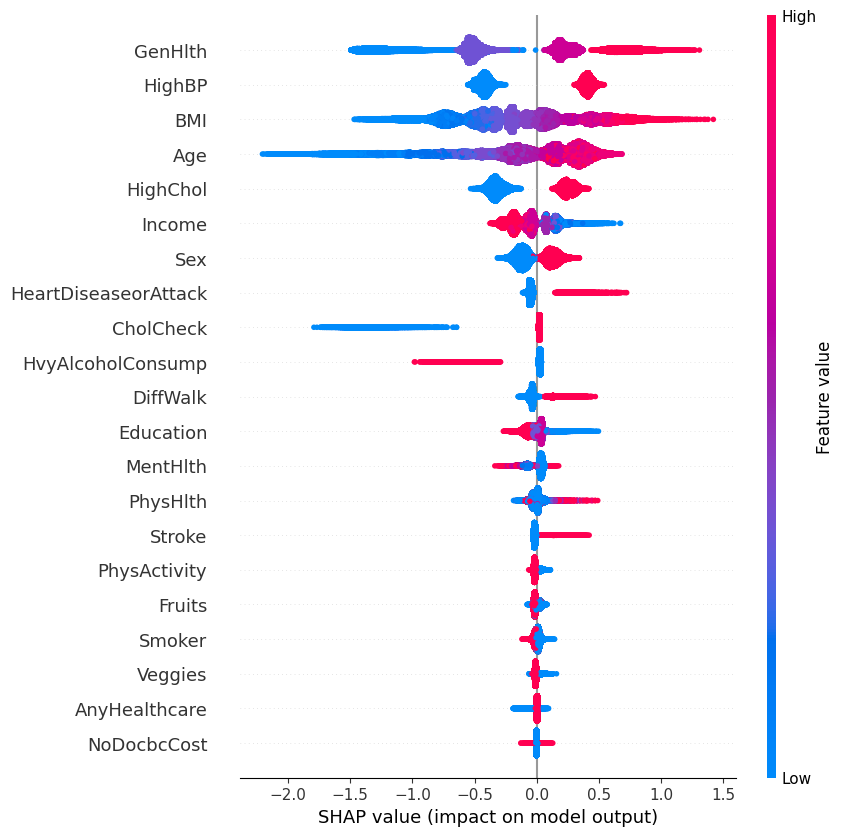

In [ ]:
# Interactive JS init
shap.initjs()

# Beeswarm for binary
shap.plots.beeswarm(shap_values, max_display=25)  # matplotlib figure